# 06 — Native-daily reliability selection and rolling-window sensitivity

## Decision in this revision

The framework now makes **two separate decisions**:

1. **Observation admissibility is native daily.** Direct VNP46A2 observations, spatial completeness (SC), temporal completeness, and dropout duration are evaluated without temporal smoothing.
2. **The primary NTL–NGCP alignment is also native daily (W=1).** The GHSL mask and SC threshold are selected using only Pearson \(r\) and retained direct-date coverage \(N\%\):

\[
S_{daily}=(N\%/100)\,\max(r,0)^2.
\]

The 4-, 7-, 14-, 21-, and 30-day windows are **sensitivity diagnostics**, not competing definitions of the primary result. They show how temporal aggregation changes alignment, paired-estimate availability, and event timing after the spatial setting has been fixed by the one-day analysis.

## Reading order and manuscript role

| Notebook block | Question answered | Manuscript role |
|---|---|---|
| Sections 1–2 | Are direct daily observations available and spatially supported? | Framework evidence; selected examples in the supplement |
| Section 3 | What did the old 30-day calculation actually do? | Reviewer-response audit; supplement only |
| Sections 4–5 | How do mask and SC threshold affect native-daily \(r\), \(N\%\), and \(S_{daily}\)? | **Primary main-paper replacement figure** |
| Section 6 | What changes at W=4–30 after the daily spatial setting is fixed? | **Main-paper sensitivity figure** |
| Sections 7–9 | Is the interpretation robust to support rules, years, and disaster timing? | Supplement |
| Appendix A | What happens under strict complete-window support? | Supplementary diagnostic only |
| Section 10 | Which current manuscript figures should be replaced, retained, or moved? | Revision checklist |

RQ1 direct VNP46A2 is studied over **2012–2024**; NGCP validation is **2013–2024**. Centered windows are retrospective descriptive tests and must not be described as near-real-time processing.


## 1. Native source signals and observability

The source-signal plots establish why reliability qualification comes before alignment. They compare direct DNB-BRDF observations with the Gap-Filled product and show SC, temporal completeness at 50%, and the longest dropout. Only the Tacloban example is displayed inline; the full POI set is still generated for the supplement.


In [1]:
from pathlib import Path
import os

import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import Image, display

DEFAULT_RQ1_ROOT = Path("/Users/S4135723/Library/CloudStorage/OneDrive-RMITUniversity/02 - CH1 - Reliability-Qualified Nighttime Lights (Technical Validation)/blackmarble-reliability-conditions")
ROOT = Path(os.environ.get("RQ1_PROJECT_ROOT", DEFAULT_RQ1_ROOT)).expanduser()
OUTPUT_ROOT = Path(os.environ.get("RQ1_NOTEBOOK06_OUTPUT", Path.cwd() / "outputs" / "notebook06_rebuilt")).expanduser()
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

PATCH_DIR = ROOT / "datasets/vnp46a2/poi_patches_5x5"
GHSL_CSV = (
    ROOT / "datasets/vnp46a2/settlement_daily_stats"
    / "SamarLeyte_DNBBRDF_AllClasses_DailyStats_2012_2024.csv"
)
FIG_DIR = OUTPUT_ROOT / "figures/source_signal_2013"
TABLE_DIR = OUTPUT_ROOT / "tables/source_signal_2013"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

DATES = pd.date_range("2013-01-01", "2013-12-31", freq="D")
HAIYAN = pd.Timestamp("2013-11-08").to_pydatetime()

POIS = {
    "Tacloban_City": "Tacloban City Center",
    "Ormoc_City": "Ormoc City Center",
    "Baybay_City": "Baybay City Center",
    "Palo": "Palo",
    "Alang_Alang": "Alang Alang",
    "Guiuan": "Guiuan",
    "Samar_Forest_Reserve": "Samar Forest Reserve",
    "Mt_Nacolod_Upland": "Mt. Nacolod Upland",
    "Central_Leyte_Forest": "Central Leyte Forest",
    "Southern_Leyte_Gulf": "Southern Leyte Gulf",
}

GHSL_CLASSES = {
    "10": "Water",
    "11": "Very low-density rural",
    "12": "Low-density rural",
    "13": "Rural cluster",
    "21": "Suburban / peri-urban",
    "22": "Semi-dense urban cluster",
    "23": "Dense urban cluster",
    "30": "Urban centre",
}

KERNELS = (1, 3, 5)
KERNEL_LABELS = {1: "1 × 1", 3: "3 × 3", 5: "5 × 5"}

In [2]:
POI_CSV = (
    ROOT / "outputs/tables/supplementary"
    / "table_sx_poi_patch_daily_metrics_long.csv"
)

if not POI_CSV.is_file():
    raise FileNotFoundError(
        f"{POI_CSV}\nRun Notebook 01 through its POI long-table export cell."
    )

poi = pd.read_csv(POI_CSV)

required = {
    "date", "location", "extent",
    "DNB_mean", "Gap_mean", "DNB_valid_px",
}
missing = required - set(poi.columns)
if missing:
    raise ValueError(f"{POI_CSV.name}: missing {sorted(missing)}")

poi["date"] = pd.to_datetime(poi["date"], errors="raise")
poi = poi[poi["date"].isin(DATES)].copy()
poi = poi[poi["location"].isin(POIS)].copy()
poi = poi[poi["extent"].isin({"1x1", "3x3", "5x5"})].copy()

if poi.duplicated(["location", "extent", "date"]).any():
    raise ValueError("Duplicate POI × extent × date rows")

poi["direct"] = pd.to_numeric(poi["DNB_mean"], errors="coerce")
poi["gap"] = pd.to_numeric(poi["Gap_mean"], errors="coerce")
poi["valid_direct_px"] = pd.to_numeric(
    poi["DNB_valid_px"], errors="coerce"
).fillna(0)

kernel_pixels = {"1x1": 1, "3x3": 9, "5x5": 25}
poi["SC"] = (
    100 * poi["valid_direct_px"] / poi["extent"].map(kernel_pixels)
)
poi["direct"] = poi["direct"].where(poi["valid_direct_px"] > 0)

POI_DAILY = (
    poi.rename(columns={"extent": "kernel"})
    .set_index(["location", "kernel", "date"])
    .sort_index()
)
POI_DAILY.to_csv(TABLE_DIR / "poi_daily_source_signals_2013.csv")

def poi_panel(location, size):
    kernel = f"{size}x{size}"
    return (
        POI_DAILY.xs((location, kernel), level=("location", "kernel"))
        .reindex(DATES)
        .rename_axis("date")
    )

print(
    f"Loaded {POI_DAILY.index.get_level_values('location').nunique()} POIs "
    f"from Notebook 01's extracted table."
)

Loaded 10 POIs from Notebook 01's extracted table.


In [3]:
if not GHSL_CSV.is_file():
    raise FileNotFoundError(GHSL_CSV)

ghsl = pd.read_csv(GHSL_CSV)

required = {"date", "ClassCode", "Mean_by_sum", "Valid_px"}
missing = required - set(ghsl.columns)
if missing:
    raise ValueError(f"{GHSL_CSV.name}: missing {sorted(missing)}")

ghsl["date"] = pd.to_datetime(ghsl["date"], errors="raise")
ghsl["ClassCode"] = (
    pd.to_numeric(ghsl["ClassCode"], errors="raise")
    .astype("Int64")
    .astype(str)
)
ghsl = ghsl[ghsl["date"].isin(DATES)].copy()
ghsl = ghsl[ghsl["ClassCode"].isin(GHSL_CLASSES)].copy()

if ghsl.duplicated(["ClassCode", "date"]).any():
    raise ValueError("Duplicate GHSL class × date records")

ghsl["Valid_px"] = pd.to_numeric(ghsl["Valid_px"], errors="coerce")
ghsl["direct"] = pd.to_numeric(ghsl["Mean_by_sum"], errors="coerce")
ghsl["direct"] = ghsl["direct"].where(ghsl["Valid_px"] > 0)

# Notebook 02's visual convention: relative class-level support.
ghsl["SC_denominator"] = (
    ghsl.groupby("ClassCode")["Valid_px"].transform("max")
)
ghsl["SC"] = np.where(
    ghsl["SC_denominator"] > 0,
    100 * ghsl["Valid_px"] / ghsl["SC_denominator"],
    np.nan,
)

# The documented class CSV has no class-level Gap-Filled field.
ghsl["gap"] = np.nan

GHSL_DAILY = ghsl.set_index(["ClassCode", "date"]).sort_index()
GHSL_DAILY.to_csv(TABLE_DIR / "ghsl_class_direct_signals_2013.csv")

def ghsl_panel(code):
    return (
        GHSL_DAILY.xs(code, level="ClassCode")
        .reindex(DATES)
        .rename_axis("date")
    )

found_classes = set(GHSL_DAILY.index.get_level_values("ClassCode"))
print(f"Loaded {len(found_classes)} GHSL classes for 2013.")

Loaded 8 GHSL classes for 2013.


In [ ]:
def plot_source_signal(title, panels, filename, direct_color="#064CEB", show_median_sd=False, display_figure=True):
    """
    panels = [(short_panel_title, dataframe), ...]
    Each dataframe has direct, gap, SC and a daily DatetimeIndex.

    A qualifying day has direct radiance and SC >= 50%.
    TC is the percentage of DATES that qualify.
    Max dropout is the longest consecutive run that does not qualify.
    """
    tau = 50.0
    ncols = len(panels)
    width = 1450 if ncols == 3 else 1000
    height = 300

    prepared = []
    for name, panel in panels:
        d = panel.reindex(DATES)
        direct = pd.to_numeric(d["direct"], errors="coerce")
        gap = pd.to_numeric(d["gap"], errors="coerce")
        sc = pd.to_numeric(d["SC"], errors="coerce")

        qualifies = direct.notna() & sc.ge(tau)
        tc = 100 * qualifies.mean()

        # Find consecutive days without a qualifying direct observation.
        dropout = (~qualifies).to_numpy()
        changes = np.diff(np.r_[False, dropout, False].astype(int))
        starts = np.flatnonzero(changes == 1)
        ends = np.flatnonzero(changes == -1)  # exclusive

        if len(starts):
            longest = int(np.argmax(ends - starts))
            max_days = int(ends[longest] - starts[longest])
            max_start = DATES[starts[longest]]
            max_end = DATES[ends[longest] - 1] + pd.Timedelta(days=1)
        else:
            max_days = 0
            max_start = max_end = None

        prepared.append(
            (name, direct, gap, sc, tc, max_days, max_start, max_end)
        )

    fig = make_subplots(
        rows=2,
        cols=ncols,
        shared_xaxes="columns",
        shared_yaxes=(ncols > 1),
        row_heights=[0.16, 0.84],
        vertical_spacing=0.06,
        horizontal_spacing=0.055 if ncols > 1 else 0.02,
        subplot_titles=[item[0] for item in prepared] + [""] * ncols,
    )

    radiance_values = []

    for col, (_, direct, gap, sc, _, max_days, max_start, max_end) in enumerate(
        prepared, start=1
    ):
        radiance_values.extend(direct.dropna().tolist())
        radiance_values.extend(gap.dropna().tolist())

        fig.add_trace(
            go.Heatmap(
                x=DATES,
                y=[0],
                z=[sc.fillna(0).to_numpy(dtype=float)],
                coloraxis="coloraxis",
                xgap=0,
                ygap=0,
                hovertemplate="%{x|%d %b %Y}<br>SC %{z:.0f}%<extra></extra>",
            ),
            row=1, col=col,
        )

        # Shade only the longest below-threshold run, in the SC strip.
        if max_days:
            fig.add_vrect(
                x0=max_start,
                x1=max_end,
                fillcolor="rgba(238, 67, 180, 0.42)",
                line_color="#D32F9D",
                line_width=1,
                layer="above",
                row=1, col=col,
            )

            fig.add_annotation(
                x=max_start + (max_end - max_start) / 2,
                y=-0.5,
                xref="x" if col == 1 else f"x{col}",
                yref="y" if col == 1 else f"y{col}",
                text=f"{max_days} d",
                showarrow=False,
                yshift=-6,
                yanchor="top",
                font=dict(color="#C42C91", size=10),
            )

        if show_median_sd and direct.notna().sum() >= 2:
            median_ntl = float(direct.median())
            sd_ntl = float(direct.std(ddof=1))

            fig.add_trace(
                go.Scatter(
                    x=[DATES[0], DATES[-1]],
                    y=[median_ntl, median_ntl],
                    mode="lines",
                    showlegend=False,
                    hoverinfo="skip",
                    line=dict(color="black", width=1.5, dash="dot"),
                ),
                row=2, col=col,
            )

            radiance_axis = ncols + col
            fig.add_annotation(
                x=1.005,                  # same paper x-position as SC colorbar
                y=median_ntl,
                xref="paper",
                yref=f"y{radiance_axis}",
                text=f"{median_ntl:.1f} ± {sd_ntl:.1f}",
                showarrow=False,
                xanchor="left",
                yanchor="middle",
                font=dict(color="black", size=10),
            )
            
        if gap.notna().any():
            fig.add_trace(
                go.Scatter(
                    x=DATES,
                    y=gap,
                    mode="lines",
                    name="Gap-Filled",
                    showlegend=(col == 1),
                    line=dict(color="#D94B40", width=1.1, shape="hv"),
                    connectgaps=False,
                ),
                row=2, col=col,
            )

        fig.add_trace(
            go.Scatter(
                x=DATES,
                y=direct,
                mode="markers",
                name="DNB-BRDF",
                showlegend=(col == 1),
                marker=dict(
                    color=direct_color,              # GHSL pixel color
                    size=6,
                    opacity=1,
                    line=dict(color="black", width=0.8),
                ),
            ),
            row=2, col=col,
        )

        # TC label: upper left of this radiance panel.
        radiance_axis = ncols + col
        fig.add_annotation(
            x=0.02,
            y=1.01,
            xref=f"x{radiance_axis} domain",
            yref=f"y{radiance_axis} domain",
            text=f"TC₅₀ = {prepared[col - 1][4]:.1f}%",
            showarrow=False,
            xanchor="left",
            yanchor="top",
            font=dict(color="#233B60", size=12),
            bgcolor="rgba(255,255,255,0.82)",
            borderpad=2,
        )
        
        for row in (1, 2):
            fig.add_vline(
                x=HAIYAN,
                row=row, col=col,
                line_color="#233B60",
                line_dash="dash",
                line_width=1.3,
            )

        fig.update_yaxes(
            range=[-0.5, 0.5],
            showticklabels=False,
            showgrid=False,
            zeroline=False,
            row=1, col=col,
        )
        fig.update_xaxes(showticklabels=False, row=1, col=col)
        fig.update_xaxes(
            range=[DATES[0], DATES[-1] + pd.Timedelta(days=1)],
            tickformat="%b",
            dtick="M2",
            row=2, col=col,
        )

    ymax = max(radiance_values) if radiance_values else 1
    for col in range(1, ncols + 1):
        fig.update_yaxes(
            range=[0, max(1, ymax * 1.04)],
            gridcolor="#E8EDF3",
            row=2, col=col,
        )

    fig.update_yaxes(title_text="SC", row=1, col=1)
    fig.update_yaxes(
        title_text="Radiance (nW·cm⁻²·sr⁻¹)",
        row=2, col=1,
    )

    fig.update_layout(
        template="plotly_white",
        width=width,
        height=height,
        title=dict(text=title, x=0.02, font=dict(size=17)),
        font=dict(color="#233B60", size=11),
        legend=dict(
            orientation="v",
            x=1.01, xanchor="right",
            y=0.85, yanchor="top",
            bgcolor="rgba(255,255,255,0.86)",
            font=dict(size=12),
        ),
        coloraxis=dict(
            colorscale="Greens",
            cmin=0,
            cmax=100,
            colorbar=dict(
                title=dict(text="SC (%)", side="top"),
                x=1.01,
                y=0.98,
                len=0.35,
                thickness=15,
                tickmode="array",
                tickvals=[0, 50, 100],
                ticktext=["0", "50", "100"],
                tickfont=dict(size=10),
            ),
        ),
        margin=dict(l=80, r=125, t=65, b=40),
        paper_bgcolor="white",
        plot_bgcolor="white",
    )

    png = FIG_DIR / f"{filename}.png"
    fig.write_html(str(FIG_DIR / f"{filename}.html"), include_plotlyjs="cdn")
    try:
        fig.write_image(str(png), width=width, height=height, scale=2)
        if display_figure:
            display(Image(filename=str(png)))
    except Exception as exc:
        if display_figure:
            fig.show()
        print(f"{filename}: HTML saved; PNG skipped ({exc})")
    return png


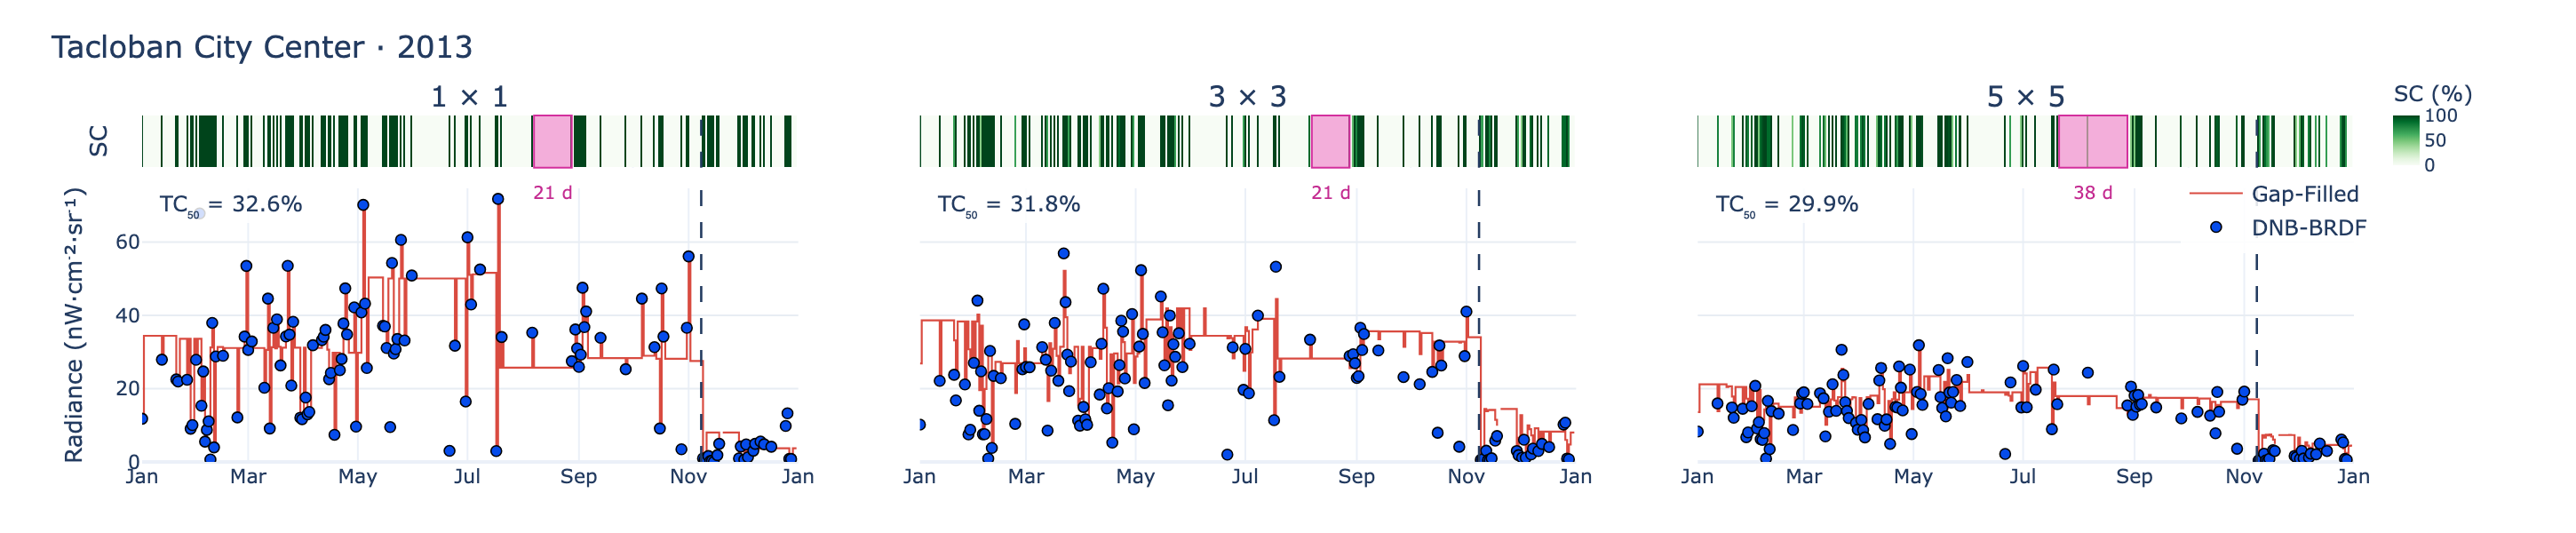

In [5]:
POI_FIGURES = {}

location = "Tacloban_City"
POI_FIGURES[location] = plot_source_signal(
    title="Tacloban City Center · 2013",
    panels=[
        (KERNEL_LABELS[size], poi_panel(location, size))
        for size in KERNELS
    ],
    filename="poi_tacloban_city_2013",
)

In [ ]:
for location, label in POIS.items():
    if location == "Tacloban_City":
        continue

    POI_FIGURES[location] = plot_source_signal(
        title=f"{label} · 2013",
        panels=[
            (KERNEL_LABELS[size], poi_panel(location, size))
            for size in KERNELS
        ],
        filename=f"poi_{location.lower()}_2013",
        display_figure=False,
    )


### Native GHSL-class observations

The GHSL-class figures repeat the daily SC and dropout diagnostics for classes 10–30. All eight are exported, but only the urban-centre example is displayed inline. These plots do not use NGCP and do not select a temporal window.


In [ ]:
GHSL_PIXEL_COLORS = {
    "10": "#7ab6f5",  # Water
    "11": "#cdf57a",  # Very low density rural
    "12": "#abcd66",  # Low density rural
    "13": "#375623",  # Rural cluster
    "21": "#ffff00",  # Suburban / peri-urban
    "22": "#a87000",  # Semi-dense urban cluster
    "23": "#732600",  # Dense urban cluster
    "30": "#ff0000",  # Urban centre
}

GHSL_FIGURES = {}

for code, label in GHSL_CLASSES.items():
    GHSL_FIGURES[code] = plot_source_signal(
        title=f"GHSL {code} · {label}",
        panels=[(f"Class {code}", ghsl_panel(code))],
        filename=f"ghsl_class_{code}_2013",
        direct_color=GHSL_PIXEL_COLORS[str(code)],
        show_median_sd=True,
        display_figure=(code == "30"),
    )


In [8]:
def daily_pair_metrics(signal, admitted, load):
    pair = pd.DataFrame({
        "ntl": signal.where(admitted),
        "load": load,
    }).dropna()

    n_pct = 100 * len(pair) / load.notna().sum()
    r = rmse_z = np.nan

    if (len(pair) >= 3
            and pair["ntl"].std(ddof=0) > 0
            and pair["load"].std(ddof=0) > 0):
        x = (pair["ntl"] - pair["ntl"].mean()) / pair["ntl"].std(ddof=0)
        y = (pair["load"] - pair["load"].mean()) / pair["load"].std(ddof=0)
        r = float(x.corr(y))
        rmse_z = float(np.sqrt(np.mean((x - y) ** 2)))

    return len(pair), n_pct, r, rmse_z

## 2. Native daily GHSL-mask evidence

These figures retain the unsmoothed daily G1–G8 observations before any temporal averaging. All four SC-threshold versions are exported, but only the 50% example is displayed inline. Their purpose is to show what the observation gate removes; they are not alignment-optimisation figures.


In [9]:
# Shared RQ1 regional inputs for the thematic-mask figures below.
from pathlib import Path
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import display

MASK_DIR = ROOT / "datasets/vnp46a2/ghsl_masked_ntl_samar_leyte"
NGCP_CSV = ROOT / "datasets/ngcp/NGCP_Hourly_Demand.csv"
OUT_DIR = OUTPUT_ROOT / "figures/supplementary"
OUT_DIR.mkdir(parents=True, exist_ok=True)
DATES = pd.date_range("2013-01-01", "2024-12-31", freq="D")

GROUPS = [
    ("G8", "10-30", "All Land", "#4E79A7"),
    ("G7", "11-30", "Rural Settlements", "#A8CE74"),
    ("G6", "12-30", "Low–Mid Rural", "#7BAF54"),
    ("G5", "13-30", "Built-Up / Rural Mix", "#375623"),
    ("G4", "21-30", "Urban Fringe", "#D9B900"),
    ("G3", "22-30", "Core & Inner", "#E6A23C"),
    ("G2", "23-30", "Dense Urban", "#A87000"),
    ("G1", "30", "Urban Core", "#D65A4A"),
]

def read_ngcp_1am():
    if not NGCP_CSV.is_file():
        raise FileNotFoundError(NGCP_CSV)
    f = pd.read_csv(NGCP_CSV, skiprows=2)
    if f.shape[1] < 4:
        raise ValueError("NGCP CSV layout differs from the RQ1 hourly file")
    f.columns = (["Date", "Coincident Peak", "Hour No"]
                 + [str(i) for i in range(1, f.shape[1] - 2)])
    f["Date"] = pd.to_datetime(f["Date"], dayfirst=True, errors="coerce").dt.normalize()
    f["1"] = pd.to_numeric(f["1"], errors="coerce")
    f = f.dropna(subset=["Date"]).set_index("Date").sort_index()
    if f.index.duplicated().any():
        raise ValueError("Duplicate NGCP dates")
    return f["1"].reindex(DATES)


In [ ]:
# None displays raw radiance. Set to 95 later to cap values at P95.
CAP_PERCENTILE = 95
MARK_ABOVE_PERCENTILE = 95
SC_THRESHOLDS = [None, 25, 50, 75]

def read_direct_mask(suffix):
    path = MASK_DIR / f"EasternVisayas_DNBBRDF_{suffix}_stats.csv"
    if not path.is_file():
        raise FileNotFoundError(path)

    d = pd.read_csv(path)
    if "date" not in d:
        if "system:index" not in d:
            raise ValueError(f"{path.name}: no date or system:index")
        d["date"] = (
            d["system:index"].astype(str)
            .str.extract(r"(\d{4}_\d{2}_\d{2})")[0]
            .str.replace("_", "-", regex=False)
        )

    d["date"] = pd.to_datetime(d["date"], errors="raise").dt.normalize()
    if d["date"].duplicated().any():
        raise ValueError(f"{path.name}: duplicate dates")

    d = d.set_index("date").sort_index()
    d["Valid_px"] = pd.to_numeric(d["Valid_px"], errors="coerce")
    d["raw"] = pd.to_numeric(d["Mean_by_sum"], errors="coerce")

    # Use the full export to define each thematic mask's SC denominator.
    denominator = d["Valid_px"].max()
    if not np.isfinite(denominator) or denominator <= 0:
        raise ValueError(f"{path.name}: no valid pixels")

    d["SC"] = 100 * d["Valid_px"] / denominator
    d["raw"] = d["raw"].where(d["Valid_px"] > 0)
    return d[["raw", "SC"]].reindex(DATES)


# Load each mask once; all four figures use identical source values.
MASK_DATA = {
    code: read_direct_mask(suffix)
    for code, suffix, label, color in GROUPS
}
LOAD = read_ngcp_1am()
ORDERED_GROUPS = list(reversed(GROUPS))  # G1 through G8

def plot_daily_masks(sc_threshold, display_figure=True):
    threshold_label = (
        "No SC threshold" if sc_threshold is None
        else f"SC ≥ {sc_threshold}%"
    )

    fig = make_subplots(
        rows=9, cols=1,
        shared_xaxes=True,
        vertical_spacing=0.012,
        row_heights=[0.18] + [0.1025] * 8,
    )

    fig.add_trace(
        go.Scattergl(
            x=DATES, y=LOAD,
            mode="lines",
            line=dict(color="#171717", width=1.7),
            name="NGCP load (1 AM)",
            connectgaps=False,
            hovertemplate=(
                "%{x|%d %b %Y}<br>%{y:.1f} MW"
                "<extra>NGCP load</extra>"
            ),
        ),
        row=1, col=1,
    )
    fig.update_yaxes(
        title_text="MW", rangemode="tozero",
        nticks=3, gridcolor="#E8EDF3",
        row=1, col=1,
    )
    fig.add_annotation(
        x=1.01, xref="paper", y=0.5, yref="y domain",
        text="NGCP load · 1 AM",
        showarrow=False, xanchor="left",
        font=dict(size=11, color="#233B60"),
    )

    coverage = []

    for row, (code, suffix, label, color) in enumerate(
        ORDERED_GROUPS, start=2
    ):
        d = MASK_DATA[code]
        raw = d["raw"]
        sc = d["SC"]

        admitted = raw.notna()
        if sc_threshold is not None:
            admitted &= sc >= sc_threshold

        # One fixed, unfiltered reference distribution per mask.
        # Its percentile does not change between the four figures.
        mark_limit = raw.quantile(MARK_ABOVE_PERCENTILE / 100)

        if CAP_PERCENTILE is None:
            shown = raw.copy()
            high = admitted & (raw > mark_limit)
        else:
            cap_limit = raw.quantile(CAP_PERCENTILE / 100)
            shown = raw.clip(upper=cap_limit)
            high = admitted & (raw > cap_limit)

        ordinary = admitted & ~high
        custom = np.column_stack([
            sc.to_numpy(dtype=float),
            raw.to_numpy(dtype=float),
        ])

        # Small dots are the actual daily direct observations.
        fig.add_trace(
            go.Scattergl(
                x=DATES,
                y=shown.where(ordinary),
                mode="markers",
                marker=dict(size=3, color=color, opacity=0.52),
                name=f"{code}: {label}",
                customdata=custom,
                hovertemplate=(
                    "%{x|%d %b %Y}<br>"
                    "Raw %{customdata[1]:.2f} nW·cm⁻²·sr⁻¹<br>"
                    "SC %{customdata[0]:.1f}%"
                    f"<extra>{code}: {label}</extra>"
                ),
            ),
            row=row, col=1,
        )

        # Open triangles identify values above the selected percentile.
        # With CAP_PERCENTILE=None, they remain at their RAW values.
        fig.add_trace(
            go.Scatter(
                x=DATES,
                y=shown.where(high),
                mode="markers",
                marker=dict(
                    symbol="triangle-up-open",
                    size=6,
                    color=color,
                    line=dict(color="#233B60", width=0.8),
                ),
                name=f"{code} upper tail",
                customdata=custom,
                hovertemplate=(
                    "%{x|%d %b %Y}<br>"
                    "Raw %{customdata[1]:.2f} nW·cm⁻²·sr⁻¹<br>"
                    "Displayed %{y:.2f}<br>"
                    "SC %{customdata[0]:.1f}%"
                    f"<extra>{code}: {label} · upper tail</extra>"
                ),
            ),
            row=row, col=1,
        )

        n_pairs, n_pct, r, rmse_z = daily_pair_metrics(
            shown, admitted, LOAD
        )

        coverage.append({
            "mask": code,
            "SC threshold": threshold_label,
            "paired days": n_pairs,
            "N%": n_pct,
            "r": r,
            "RMSE_z": rmse_z,
        })

        fig.update_yaxes(
            rangemode="tozero", nticks=3,
            gridcolor="#E8EDF3",
            tickfont=dict(size=10),
            row=row, col=1,
        )

        r_text = "—" if not np.isfinite(r) else f"{r:.2f}"
        rmse_text = "—" if not np.isfinite(rmse_z) else f"{rmse_z:.2f}"

        fig.add_annotation(
            x=1.01, xref="paper",
            y=0.5, yref=f"y{row} domain",
            text=(
                f"{code} · {label}<br>"
                f"r = {r_text}<br>"
                f"RMSE (z) = {rmse_text}<br>"
                f"N% = {n_pct:.1f}%"
            ),
            showarrow=False,
            xanchor="left",
            align="left",
            font=dict(size=10, color="#233B60"),
        )

    for day, label in [
        ("2013-11-08", "Haiyan"),
        ("2021-12-16", "Rai"),
    ]:
        event = pd.Timestamp(day)
        for row in range(1, 10):
            fig.add_vline(
                x=event, row=row, col=1,
                line_dash="dash",
                line_color="#233B60",
                line_width=1,
            )
        fig.add_annotation(
            x=event, y=1.005, yref="paper",
            text=label, showarrow=False,
            yanchor="bottom", bgcolor="white",
            font=dict(size=11, color="#233B60"),
        )

    fig.update_xaxes(
        range=[DATES[0], DATES[-1]],
        dtick="M24", tickformat="%Y",
        gridcolor="#E8EDF3",
    )
    fig.update_xaxes(title_text="Date", row=9, col=1)

    fig.add_annotation(
        x=-0.075, xref="paper",
        y=0.41, yref="paper",
        text="Radiance (nW·cm⁻²·sr⁻¹)",
        textangle=-90, showarrow=False,
        font=dict(size=12, color="#233B60"),
    )

    cap_label = (
        "raw radiance" if CAP_PERCENTILE is None
        else f"P{CAP_PERCENTILE} display cap"
    )
    fig.update_layout(
        template="plotly_white",
        width=1250, height=1050,
        title=dict(
            text=f"Daily DNB-BRDF by GHSL mask · {threshold_label}"
                 f" · 2013–2024 · {cap_label}",
            x=0.04,
        ),
        showlegend=False,
        font=dict(color="#233B60", size=11),
        margin=dict(l=110, r=220, t=90, b=65),
        paper_bgcolor="white",
        plot_bgcolor="white",
    )

    if display_figure:
        fig.show()

    tag = "none" if sc_threshold is None else str(sc_threshold)
    png = OUT_DIR / f"ghsl_daily_sc_{tag}_raw.png"
    try:
        fig.write_image(str(png), scale=2)
        print("Saved:", png)
    except Exception as exc:
        print(f"Figure displayed; PNG export unavailable: {exc}")

    return coverage


all_coverage = []
for threshold in SC_THRESHOLDS:
    all_coverage.extend(plot_daily_masks(threshold, display_figure=(threshold == 50)))

display(
    pd.DataFrame(all_coverage)
    .pivot(index="mask", columns="SC threshold", values="N%")
    .round(1)
)


## 3. Audit of the original 30-day calculation

Notebook 03 first removed dates failing the SC threshold, then applied `rolling(30, min_periods=1, center=True)` to the remaining NTL **rows**. For NTL, 30 therefore meant 30 accepted observations; for daily NGCP it meant approximately 30 calendar days. The comparison below documents that mismatch. It is reviewer-response evidence, not a candidate figure for the main paper.


In [13]:
# Load the complete 2012–2024 RQ1 mask exports; NGCP scoring starts in 2013.
SOURCE_DATES = pd.date_range('2012-01-19', '2024-12-31', freq='D', name='date')
VALIDATION_DATES = pd.date_range('2013-01-01', '2024-12-31', freq='D', name='date')
W_VALUES = np.arange(1, 31)
DISPLAY_TAUS = np.arange(0., 101., 1.)  # only the display grid; selection uses exact SC cutoffs
P95_ANALYSIS_CAP = 95                  # Notebook 03's 0th–95th percentile winsorisation
SENS_DIR = OUTPUT_ROOT / 'corrected_window_sensitivity'
SENS_DIR.mkdir(parents=True, exist_ok=True)

def full_mask_export(suffix):
    path = MASK_DIR / f'EasternVisayas_DNBBRDF_{suffix}_stats.csv'
    if not path.is_file():
        raise FileNotFoundError(path)
    d = pd.read_csv(path)
    if 'date' not in d.columns:
        if 'system:index' not in d.columns:
            raise ValueError(f'{path.name}: date and system:index are both absent')
        d['date'] = (d['system:index'].astype(str)
                     .str.extract(r'(\d{4}_\d{2}_\d{2})')[0]
                     .str.replace('_', '-', regex=False))
    d['date'] = pd.to_datetime(d['date'], errors='raise').dt.normalize()
    if d['date'].duplicated().any():
        raise ValueError(f'{path.name}: duplicate dates')
    d = d.set_index('date').sort_index()
    required = {'Valid_px', 'Mean_by_sum'}
    if not required.issubset(d.columns):
        raise ValueError(f'{path.name}: missing {sorted(required - set(d.columns))}')
    valid_px = pd.to_numeric(d['Valid_px'], errors='coerce')
    raw = pd.to_numeric(d['Mean_by_sum'], errors='coerce').where(valid_px > 0)
    denominator = valid_px.loc[raw.notna()].max()
    if not np.isfinite(denominator) or denominator <= 0:
        raise ValueError(f'{path.name}: no direct observations')
    sc = 100 * valid_px / denominator
    low, high = raw.quantile(0), raw.quantile(P95_ANALYSIS_CAP / 100)
    ntl = raw.clip(lower=low, upper=high)
    return (pd.DataFrame({'raw': raw, 'ntl': ntl, 'SC': sc, 'Valid_px': valid_px})
            .reindex(SOURCE_DATES)), {'source': str(path), 'SC_denominator': denominator,
                                      'P95_cap': high, 'direct_dates': int(raw.notna().sum())}

SENS_MASK_DATA = {}
source_rows = []
for code, suffix, label, color in reversed(GROUPS):
    SENS_MASK_DATA[code], audit = full_mask_export(suffix)
    source_rows.append({'mask': code, 'label': label, **audit})
SOURCE_AUDIT = pd.DataFrame(source_rows)
display(SOURCE_AUDIT)
SOURCE_AUDIT.to_csv(SENS_DIR / 'source_audit.csv', index=False)

SENS_LOAD = LOAD.reindex(SOURCE_DATES).astype(float)
VALIDATION_ENDPOINT = ((SOURCE_DATES >= VALIDATION_DATES[0])
                       & (SOURCE_DATES <= VALIDATION_DATES[-1])
                       & SENS_LOAD.notna().to_numpy())
N_POSSIBLE = int(VALIDATION_ENDPOINT.sum())
if N_POSSIBLE == 0:
    raise ValueError('No observed NGCP 1 AM dates in 2013–2024')
print(f'NGCP comparison dates, 2013–2024: {N_POSSIBLE:,}')

,mask,label,source,SC_denominator,P95_cap,direct_dates
0,G1,Urban Core,/Users/S4135723/Library/CloudStorage/OneDrive-...,449,6.969696,3097
1,G2,Dense Urban,/Users/S4135723/Library/CloudStorage/OneDrive-...,1492,3.743223,3592
2,G3,Core & Inner,/Users/S4135723/Library/CloudStorage/OneDrive-...,2782,2.390047,3759
3,G4,Urban Fringe,/Users/S4135723/Library/CloudStorage/OneDrive-...,11480,1.186523,3847
4,G5,Built-Up / Rural Mix,/Users/S4135723/Library/CloudStorage/OneDrive-...,15528,1.022804,3910
5,G6,Low–Mid Rural,/Users/S4135723/Library/CloudStorage/OneDrive-...,30549,0.822862,3941
6,G7,Rural Settlements,/Users/S4135723/Library/CloudStorage/OneDrive-...,87035,0.644418,3960
7,G8,All Land,/Users/S4135723/Library/CloudStorage/OneDrive-...,88991,0.637115,3962


NGCP comparison dates, 2013–2024: 4,383


In [14]:
def paired_alignment(x, y):
    paired = pd.DataFrame({'ntl': x, 'load': y}).reindex(SOURCE_DATES)
    paired = paired.loc[VALIDATION_ENDPOINT].dropna()
    n = len(paired)
    r = np.nan
    if n >= 3 and paired.ntl.std(ddof=0) > 0 and paired.load.std(ddof=0) > 0:
        r = float(paired.ntl.corr(paired.load))
    return {'n_pairs': n, 'N_pct': 100 * n / N_POSSIBLE, 'r': r,
            'RMSE_z': float(np.sqrt(max(0, 2 * (1 - r)))) if np.isfinite(r) else np.nan}

AUDIT_MASK, AUDIT_TAU, AUDIT_W = 'G3', 10., 30
aud = SENS_MASK_DATA[AUDIT_MASK]
accepted = aud.ntl.notna() & aud.SC.ge(AUDIT_TAU)
legacy_ntl = aud.loc[accepted, 'ntl'].rolling(AUDIT_W, min_periods=1, center=True).mean()
calendar_ntl = aud.ntl.where(accepted).rolling(AUDIT_W, min_periods=1, center=True).mean()
calendar_load = SENS_LOAD.rolling(AUDIT_W, min_periods=1, center=True).mean()

METHOD_AUDIT = pd.DataFrame([
    {'method': 'Original: 30 retained NTL observations',
     **paired_alignment(legacy_ntl, calendar_load)},
    {'method': 'Corrected: 30 calendar days for both',
     **paired_alignment(calendar_ntl, calendar_load)},
])
display(METHOD_AUDIT.round(3))
METHOD_AUDIT.to_csv(SENS_DIR / 'legacy_vs_calendar_30_day_audit.csv', index=False)

zoom = pd.date_range('2013-05-01', '2014-05-31', freq='D')
f = make_subplots(rows=2, cols=1, shared_xaxes=True, vertical_spacing=.09,
                  row_heights=[.17, .83], specs=[[{}], [{'secondary_y': True}]],
                  subplot_titles=['SC (%)', 'Centered 30-day means'])
f.add_trace(go.Heatmap(x=zoom, y=[0], z=[aud.SC.reindex(zoom).fillna(0).to_numpy()],
                       zmin=0, zmax=100, colorscale='Greens',
                       colorbar=dict(title='SC %', len=.33, y=.93, x=1.01),
                       hovertemplate='%{x|%d %b %Y}<br>SC %{z:.1f}%<extra></extra>'), row=1, col=1)
for series, name, color, dash in [
    (legacy_ntl, 'Original: 30 retained NTL observations', '#D65A4A', 'dot'),
    (calendar_ntl, 'NTL: 30 calendar days', '#2952CC', 'solid'),
]:
    f.add_trace(go.Scatter(x=zoom, y=series.reindex(zoom), mode='lines', name=name,
                           line=dict(color=color, width=2, dash=dash), connectgaps=False), row=2, col=1)
f.add_trace(go.Scatter(x=zoom, y=calendar_load.reindex(zoom), mode='lines',
                       name='NGCP: 30 calendar days',
                       line=dict(color='#202020', width=2)), row=2, col=1,
            secondary_y=True)
f.add_vline(x=pd.Timestamp('2013-11-08'), line_dash='dash', line_color='#233B60')
f.update_yaxes(title_text='Radiance', row=2, col=1, secondary_y=False)
f.update_yaxes(title_text='NGCP load (MW)', row=2, col=1, secondary_y=True,
               showgrid=False)
f.update_yaxes(showticklabels=False, row=1, col=1)
f.update_layout(template='plotly_white', width=1200, height=500,
                title='Why the old “30 days” was not a common calendar window',
                legend=dict(orientation='h', y=-.18),
                margin=dict(l=75, r=100, t=80, b=95), font=dict(color='#233B60'))
f.show()
f.write_html(SENS_DIR / 'original_vs_calendar_30_day.html', include_plotlyjs='cdn')

,method,n_pairs,N_pct,r,RMSE_z
0,Original: 30 retained NTL observations,2522,57.54,0.793,0.643
1,Corrected: 30 calendar days for both,4383,100.00,0.774,0.672


In [15]:
PROFILE_GROUPS = ("G1", "G8")
PROFILE_WINDOWS = (1, 4, 7, 14, 21, 30)
PROFILE_LEFT = pd.Timestamp("2013-05-01")
PROFILE_RIGHT = pd.Timestamp("2014-05-31")
HAIYAN_DATE = pd.Timestamp("2013-11-08")

GROUP_STYLE = {
    code: (label, color)
    for code, suffix, label, color in GROUPS
}
profile_dates = pd.date_range(
    PROFILE_LEFT, PROFILE_RIGHT, freq="D"
)
daily_load = SENS_LOAD.reindex(SOURCE_DATES).astype(float)
load_limit = 1.08 * float(
    daily_load.reindex(profile_dates).max()
)

PROFILE_FIGURES = {}
profile_rows = []

for code in PROFILE_GROUPS:
    label, color = GROUP_STYLE[code]

    # Every available direct date; no SC threshold.
    direct_ntl = (
        SENS_MASK_DATA[code]["ntl"]
        .reindex(SOURCE_DATES)
        .astype(float)
    )
    ntl_limit = 1.08 * float(
        direct_ntl.reindex(profile_dates).max()
    )

    fig = make_subplots(
        rows=2,
        cols=3,
        specs=[
            [{"secondary_y": True} for _ in range(3)]
            for _ in range(2)
        ],
        shared_xaxes=True,
        horizontal_spacing=.085,
        vertical_spacing=.16,
        subplot_titles=[
            f"W={width} d" for width in PROFILE_WINDOWS
        ],
    )
    for heading in fig.layout.annotations:
        heading.font = dict(
            size=16, color="#233B60"
        )

    panel_legends = {}

    for i, width in enumerate(PROFILE_WINDOWS):
        row, col = i // 3 + 1, i % 3 + 1
        legend_id = (
            "legend" if i == 0 else f"legend{i + 1}"
        )

        ntl_mean = direct_ntl.rolling(
            width, min_periods=1, center=True
        ).mean()
        load_mean = daily_load.rolling(
            width, min_periods=1, center=True
        ).mean()

        metrics = paired_alignment(
            ntl_mean, load_mean
        )
        profile_rows.append({
            "mask": code,
            "window_days": width,
            **metrics,
        })

        r_text = (
            f"{metrics['r']:.2f}"
            if np.isfinite(metrics["r"]) else "NA"
        )
        ntl_legend = (
            f"{code} · r={r_text} · "
            f"N%={metrics['N_pct']:.1f}"
        )

        # The direct observations remain visible behind the mean.
        fig.add_trace(
            go.Scatter(
                x=profile_dates,
                y=direct_ntl.reindex(profile_dates),
                mode="markers",
                name=ntl_legend,
                legend=legend_id,
                showlegend=(width == 1),
                marker=dict(
                    color=color,
                    size=4,
                    opacity=.55 if width == 1 else .22,
                ),
            ),
            row=row, col=col, secondary_y=False,
        )

        fig.add_trace(
            go.Scatter(
                x=profile_dates,
                y=ntl_mean.reindex(profile_dates),
                mode="lines",
                name=ntl_legend,
                legend=legend_id,
                showlegend=(width != 1),
                connectgaps=False,
                line=dict(color=color, width=2.2),
            ),
            row=row, col=col, secondary_y=False,
        )

        fig.add_trace(
            go.Scatter(
                x=profile_dates,
                y=load_mean.reindex(profile_dates),
                mode="lines",
                name="NGCP 1 AM",
                legend=legend_id,
                showlegend=True,
                connectgaps=False,
                line=dict(
                    color="#202020", width=1.8
                ),
            ),
            row=row, col=col, secondary_y=True,
        )

        fig.add_vline(
            x=HAIYAN_DATE,
            row=row, col=col,
            line_color="#233B60",
            line_dash="dash",
            line_width=1.2,
        )

        fig.update_xaxes(
            range=[PROFILE_LEFT, PROFILE_RIGHT],
            dtick="M2",
            tickformat="%b %Y",
            tickangle=-30,
            showticklabels=True,
            gridcolor="#E8EDF3",
            row=row, col=col,
        )
        fig.update_yaxes(
            range=[0, ntl_limit],
            showticklabels=(col == 1),
            title_text=(
                "Radiance (nW·cm⁻²·sr⁻¹)"
                if col == 1 else None
            ),
            gridcolor="#E8EDF3",
            row=row, col=col,
            secondary_y=False,
        )
        fig.update_yaxes(
            range=[0, load_limit],
            showticklabels=(col == 3),
            title_text=(
                "NGCP load (MW)"
                if col == 3 else None
            ),
            showgrid=False,
            row=row, col=col,
            secondary_y=True,
        )

        # Position this panel's own two-item legend inside it.
        xaxis_key = (
            "xaxis" if i == 0 else f"xaxis{i + 1}"
        )
        primary_y_key = (
            "yaxis" if i == 0
            else f"yaxis{2 * i + 1}"
        )
        x_domain = fig.layout[xaxis_key].domain
        y_domain = fig.layout[primary_y_key].domain

        panel_legends[legend_id] = dict(
            x=x_domain[1] - .01,
            y=y_domain[1] - .01,
            xanchor="right",
            yanchor="top",
            bgcolor="rgba(255,255,255,.85)",
            font=dict(size=10),
            borderwidth=0,
        )

    fig.update_layout(
        template="plotly_white",
        width=1550,
        height=820,
        title=dict(
            text=f"{code} · {label} | no SC threshold",
            x=.02,
            font=dict(size=17),
        ),
        margin=dict(
            l=95, r=95, t=85, b=95
        ),
        font=dict(
            family="Arial",
            color="#233B60",
            size=12,
        ),
        paper_bgcolor="white",
        plot_bgcolor="white",
        **panel_legends,
    )

    fig.add_annotation(
        x=.5, y=-.12,
        xref="paper", yref="paper",
        text=(
            "Lines: Haiyan zoom · "
            "Legend r and N%: full 2013–2024 comparison"
        ),
        showarrow=False,
        font=dict(size=11, color="#233B60"),
    )

    fig.show()
    fig.write_html(
        SENS_DIR / f"{code.lower()}_six_window_profiles.html",
        include_plotlyjs="cdn",
    )
    PROFILE_FIGURES[code] = fig

PROFILE_METRICS = pd.DataFrame(profile_rows)

## 4. Corrected common-calendar sensitivity cube

The full cube tests every G1–G8 mask, every effective SC cutoff in 0–100%, and every centered calendar width W=1–30. Both qualified NTL and NGCP are averaged over the same calendar width with `min_periods=1`.

This cube is retained for transparency, but **window length is not optimised for the primary result**. Section 5 selects mask and SC threshold from the W=1 slice only. Later sections hold that daily-selected spatial setting fixed and ask what longer windows change.

Two coverage quantities remain distinct:

- `direct_pct`: dates with an SC-qualified direct NTL observation; this is the observability quantity.
- `N_pct`: dates with both rolling estimates; at W>1 this can bridge missing days and must not be called direct satellite coverage.

Paired z-score RMSE is reported in the data table but is not used in the score because, on identical paired dates, `RMSE_z² = 2(1-r)` and would double-count alignment.


In [16]:
from time import perf_counter

SMOOTHED_LOAD = {
    w: SENS_LOAD.rolling(w, min_periods=1, center=True).mean().to_numpy(dtype=float)
    for w in W_VALUES
}

def exact_threshold_sweep(code, width):
    d = SENS_MASK_DATA[code]
    x = d.ntl.to_numpy(dtype=float)
    sc = d.SC.to_numpy(dtype=float)
    observed = np.isfinite(x) & np.isfinite(sc)
    values = np.where(observed, x, 0.)
    y = SMOOTHED_LOAD[width]
    endpoint_ok = VALIDATION_ENDPOINT & np.isfinite(y)
    size = len(x)

    # Start with every observed direct day admitted (τ=0).
    count = (pd.Series(observed.astype(int), index=SOURCE_DATES)
             .rolling(width, min_periods=1, center=True).sum()
             .to_numpy(dtype=int))
    total = (pd.Series(values, index=SOURCE_DATES)
             .rolling(width, min_periods=1, center=True).sum()
             .to_numpy(dtype=float))
    mean = np.divide(total, count, out=np.zeros(size), where=count > 0)
    pair = endpoint_ok & (count > 0)
    xx, yy = mean[pair], y[pair]
    n = int(pair.sum())
    sx, sy = float(xx.sum()), float(yy.sum())
    sxx, syy, sxy = float((xx * xx).sum()), float((yy * yy).sum()), float((xx * yy).sum())
    support_sum = float(count[pair].sum())
    direct_n = int((observed & VALIDATION_ENDPOINT).sum())

    days = np.flatnonzero(observed)
    days = days[np.argsort(sc[days], kind='stable')]
    taus = np.unique(np.r_[0., 100., sc[days]])
    position = 0
    rows = []
    label = next(label for c, suffix, label, color in GROUPS if c == code)

    for tau in taus:
        # Move from one exact SC cutoff to the next by removing only
        # observations that no longer qualify. Each affects at most W endpoints.
        while position < len(days) and sc[days[position]] < tau:
            i = int(days[position])
            position += 1
            lo = max(0, i - (width - 1) // 2)
            hi = min(size, i + width // 2 + 1)
            old_count = count[lo:hi].copy()
            old_total = total[lo:hi].copy()
            segment_y = y[lo:hi]
            allowed = endpoint_ok[lo:hi]
            old_mean = np.divide(old_total, old_count,
                                 out=np.zeros(len(old_count)), where=old_count > 0)
            old_pair = (old_count > 0) & allowed
            old_x, old_y = old_mean[old_pair], segment_y[old_pair]
            n -= int(old_pair.sum())
            sx -= float(old_x.sum()); sy -= float(old_y.sum())
            sxx -= float((old_x * old_x).sum()); syy -= float((old_y * old_y).sum())
            sxy -= float((old_x * old_y).sum())
            support_sum -= float(old_count[old_pair].sum())

            new_count = old_count - 1
            new_total = old_total - x[i]
            new_total[new_count == 0] = 0.
            count[lo:hi] = new_count
            total[lo:hi] = new_total
            new_mean = np.divide(new_total, new_count,
                                 out=np.zeros(len(new_count)), where=new_count > 0)
            new_pair = (new_count > 0) & allowed
            new_x, new_y = new_mean[new_pair], segment_y[new_pair]
            n += int(new_pair.sum())
            sx += float(new_x.sum()); sy += float(new_y.sum())
            sxx += float((new_x * new_x).sum()); syy += float((new_y * new_y).sum())
            sxy += float((new_x * new_y).sum())
            support_sum += float(new_count[new_pair].sum())
            if VALIDATION_ENDPOINT[i]:
                direct_n -= 1

        r = np.nan
        if n >= 3:
            vx = sxx - sx * sx / n
            vy = syy - sy * sy / n
            tol_x = np.finfo(float).eps * max(1., abs(sxx))
            tol_y = np.finfo(float).eps * max(1., abs(syy))
            if vx > tol_x and vy > tol_y:
                r = float(np.clip((sxy - sx * sy / n) / np.sqrt(vx * vy), -1, 1))
        rmse_z = float(np.sqrt(max(0, 2 * (1 - r)))) if np.isfinite(r) else np.nan
        n_fraction = n / N_POSSIBLE
        score = n_fraction * max(r, 0)**2 if np.isfinite(r) else 0.
        rows.append((code, label, int(width), float(tau), n, N_POSSIBLE,
                     100 * n_fraction, direct_n, 100 * direct_n / N_POSSIBLE,
                     support_sum / n if n else np.nan,
                     100 * support_sum / (n * width) if n else np.nan,
                     r, rmse_z, score))
    return rows

start_sweep = perf_counter()
sweep_rows = []
for code, suffix, label, color in reversed(GROUPS):
    for width in W_VALUES:
        sweep_rows.extend(exact_threshold_sweep(code, int(width)))

SENSITIVITY = pd.DataFrame(sweep_rows, columns=[
    'mask', 'label', 'window_days', 'tau', 'n_pairs', 'n_possible',
    'N_pct', 'direct_n', 'direct_pct', 'mean_direct_days',
    'mean_window_support_pct', 'r', 'RMSE_z', 'score',
])
SENSITIVITY.to_csv(SENS_DIR / 'complete_mask_sc_window_surface.csv.gz',
                   compression='gzip', index=False)
print(f'{len(SENSITIVITY):,} exact configurations evaluated in '
      f'{(perf_counter() - start_sweep):.1f} seconds.')
print('Full exact table:', SENS_DIR / 'complete_mask_sc_window_surface.csv.gz')
display(SENSITIVITY.groupby('mask').agg(
    configurations=('tau', 'size'),
    distinct_tau=('tau', 'nunique'),
    windows=('window_days', 'nunique'),
))

605,970 exact configurations evaluated in 28.3 seconds.
Full exact table: /Users/S4135723/Library/CloudStorage/OneDrive-RMITUniversity/02 - CH1 - Reliability-Qualified Nighttime Lights (Technical Validation)/blackmarble-reliability-conditions/notebooks/outputs/notebook06_rebuilt/corrected_window_sensitivity/complete_mask_sc_window_surface.csv.gz


,configurations,distinct_tau,windows
mask,,,
G1,13470,449,30
G2,37740,1258,30
G3,56040,1868,30
G4,87600,2920,30
G5,93600,3120,30
G6,101160,3372,30
G7,107910,3597,30
G8,108450,3615,30


## 4.1 Full joint sensitivity surfaces — supplement

These surfaces expose the entire mask × SC × window search. Use the \(r\) and paired-estimate \(N\%\) surfaces as supplementary evidence. They show why window length, spatial completeness, and thematic mask must not be collapsed into a single unexplained choice.


In [17]:
# Retain all fields for later figures and hover.
# Draw only r and paired-window N% here.
MAP_METRICS = (
    "r", "RMSE_z", "N_pct", "direct_pct",
    "mean_direct_days", "mean_window_support_pct",
    "score", "n_pairs",
)

SENS_MAPS = {metric: {} for metric in MAP_METRICS}
for code, suffix, label, color in reversed(GROUPS):
    for metric in MAP_METRICS:
        SENS_MAPS[metric][code] = np.full(
            (len(DISPLAY_TAUS), len(W_VALUES)), np.nan
        )

    for width in W_VALUES:
        q = SENSITIVITY[
            (SENSITIVITY["mask"] == code)
            & (SENSITIVITY.window_days == width)
        ].sort_values("tau")

        exact_tau = q.tau.to_numpy()
        ix = np.minimum(
            np.searchsorted(
                exact_tau, DISPLAY_TAUS, side="left"
            ),
            len(q) - 1,
        )
        for metric in MAP_METRICS:
            SENS_MAPS[metric][code][:, width - 1] = (
                q[metric].to_numpy()[ix]
            )


# Display-only transformations. Metrics are never changed.
R_COLOUR_POWER = 2.
N_COLOUR_POWER = 3.

R_TICKS = np.array([-1., -.5, 0., .5, .75, 1.])
R_COLOUR_TICKS = (
    np.sign(R_TICKS)
    * np.abs(R_TICKS)**R_COLOUR_POWER
)

N_TICKS = np.array([0, 50, 75, 90, 100], dtype=float)
N_COLOUR_TICKS = (
    N_TICKS / 100
)**N_COLOUR_POWER

HEATMAPS = [
    dict(
        metric="r",
        palette="jet_r",
        low=-1,
        high=1,
        colorbar="Pearson r",
        ticks=R_COLOUR_TICKS,
        ticktext=[f"{v:g}" for v in R_TICKS],
    ),
    dict(
        metric="N_pct",
        palette="Viridis",
        low=0,
        high=1,
        colorbar="N% paired",
        ticks=N_COLOUR_TICKS,
        ticktext=[f"{v:g}%" for v in N_TICKS],
    ),
]


def sensitivity_heatmap(spec):
    metric = spec["metric"]
    ordered = list(reversed(GROUPS))

    fig = make_subplots(
        rows=2,
        cols=4,
        shared_xaxes=True,
        shared_yaxes=True,
        horizontal_spacing=.04,
        vertical_spacing=.15,
        subplot_titles=[
            f"{code} · {label}"
            for code, suffix, label, color in ordered
        ],
    )
    for heading in fig.layout.annotations:
        heading.font = dict(
            family="Arial",
            size=20,
            color="#233B60",
        )

    for i, (code, suffix, label, color) in enumerate(ordered):
        row, col = i // 4 + 1, i % 4 + 1
        raw = SENS_MAPS[metric][code]

        if metric == "r":
            colour_value = (
                np.sign(raw)
                * np.abs(raw)**R_COLOUR_POWER
            )
        else:
            colour_value = (
                raw / 100
            )**N_COLOUR_POWER

        detail = np.dstack([
            SENS_MAPS[m][code]
            for m in (
                "r", "RMSE_z", "N_pct", "direct_pct",
                "mean_direct_days",
                "mean_window_support_pct",
                "n_pairs",
            )
        ])

        fig.add_trace(
            go.Heatmap(
                x=W_VALUES,
                y=DISPLAY_TAUS,
                z=colour_value,
                customdata=detail,
                coloraxis="coloraxis",
                xgap=0,
                ygap=0,
                hoverongaps=False,
                hovertemplate=(
                    "Calendar window W %{x} d · "
                    "SC τ %{y:.0f}%<br>"
                    "Pearson r %{customdata[0]:.3f}<br>"
                    "Paired z-score RMSE "
                    "%{customdata[1]:.3f}<br>"
                    "N% paired window estimates "
                    "%{customdata[2]:.1f}% "
                    "(%{customdata[6]:.0f} dates)<br>"
                    "N% directly observed dates "
                    "%{customdata[3]:.1f}%<br>"
                    "Mean direct days / W "
                    "%{customdata[4]:.1f}<br>"
                    "Mean direct fraction / W "
                    "%{customdata[5]:.1f}%"
                    f"<extra>{code}</extra>"
                ),
            ),
            row=row, col=col,
        )

        # Visible black boundary around every panel.
        axis_name = "" if i == 0 else str(i + 1)
        fig.add_shape(
            type="rect",
            xref=f"x{axis_name}",
            yref=f"y{axis_name}",
            x0=.5,
            x1=30.5,
            y0=-.5,
            y1=100.5,
            line=dict(
                color="#000000",
                width=2,
            ),
            fillcolor="rgba(0,0,0,0)",
            layer="above",
        )

        fig.update_xaxes(
            range=[.5, 30.5],
            tickvals=[1, 4, 7, 14, 21, 30],
            showticklabels=True,
            tickfont=dict(size=16),
            title_text=(
                "Calendar window W (days)"
                if row == 2 else None
            ),
            title_font=dict(size=18),
            showline=False,
            ticks="outside",
            ticklen=4,
            row=row, col=col,
        )
        fig.update_yaxes(
            range=[-.5, 100.5],
            tickvals=[0, 25, 50, 75, 100],
            showticklabels=(col == 1),
            tickfont=dict(size=16),
            title_text=(
                "SC threshold τ (%)"
                if col == 1 else None
            ),
            title_font=dict(size=18),
            showline=False,
            ticks="outside",
            ticklen=4,
            row=row, col=col,
        )

    colorbar = dict(
        title=dict(
            text=spec["colorbar"],
            side="top",
            font=dict(
                size=18,
                color="#233B60",
            ),
        ),
        x=1.015,
        y=.5,
        len=.78,
        thickness=22,
        tickfont=dict(size=16),
        tickvals=spec["ticks"],
        ticktext=spec["ticktext"],
    )

    fig.update_layout(
        template="plotly_white",
        width=1900,
        height=900,
        coloraxis=dict(
            colorscale=spec["palette"],
            cmin=spec["low"],
            cmax=spec["high"],
            colorbar=colorbar,
        ),
        showlegend=False,
        margin=dict(
            l=105, r=150, t=70, b=85
        ),
        font=dict(
            family="Arial",
            color="#233B60",
            size=17,
        ),
        paper_bgcolor="white",
        plot_bgcolor="#E9EDF2",
    )

    fig.show()
    stem = f"full_surface_{metric}"
    fig.write_html(
        SENS_DIR / f"{stem}.html",
        include_plotlyjs="cdn",
    )
    try:
        fig.write_image(
            str(SENS_DIR / f"{stem}.png"),
            scale=2,
        )
    except Exception as exc:
        print(
            f"{stem}: HTML saved; "
            f"PNG unavailable ({exc})"
        )
    return fig


FULL_SURFACE_FIGURES = {
    spec["metric"]: sensitivity_heatmap(spec)
    for spec in HEATMAPS
}

### Supplement view A — fix SC, vary the common window

The six SC facets are cross-sections through the full cube. They show how apparent alignment and paired-estimate availability change with smoothing. They are not optimisation runs.


In [18]:
SLICE_TAUS = [0, 10, 25, 50, 75, 90]
LABEL_WINDOWS = (7, 14, 30)
WINDOW_SLICE_COLORS = {
    code: color for code, suffix, label, color in GROUPS
}
WINDOW_SLICE_WIDTH, WINDOW_SLICE_HEIGHT = 1800, 850
WINDOW_SLICE_MARGIN = dict(l=95, r=230, t=100, b=95)


def plot_window_slices(metric, ylabel, stem):
    if metric not in ("r", "RMSE_z", "N_pct", "score"):
        raise ValueError(metric)

    is_r = metric == "r"
    is_n = metric == "N_pct"
    is_rmse = metric == "RMSE_z"

    fig = make_subplots(
        rows=2, cols=3,
        shared_xaxes=True,
        shared_yaxes=True,
        horizontal_spacing=0.06,
        vertical_spacing=0.16,
        subplot_titles=[f"SC τ={tau}%" for tau in SLICE_TAUS],
    )
    for heading in fig.layout.annotations:
        heading.font = dict(
            family="Arial", size=19, color="#233B60"
        )

    for j, tau in enumerate(SLICE_TAUS):
        row, col = j // 3 + 1, j % 3 + 1
        axis_number = j + 1
        axis_x = "x" if axis_number == 1 else f"x{axis_number}"
        axis_y = "y" if axis_number == 1 else f"y{axis_number}"

        for code, suffix, label, color in reversed(GROUPS):
            values = SENS_MAPS[metric][code][tau, :]
            shown = (
                np.where(values > 0, values, np.nan)
                if is_n else values
            )
            custom = np.column_stack([
                SENS_MAPS["N_pct"][code][tau, :],
                SENS_MAPS["direct_pct"][code][tau, :],
                SENS_MAPS["mean_window_support_pct"][code][tau, :],
            ])

            fig.add_trace(
                go.Scatter(
                    x=W_VALUES,
                    y=shown,
                    mode="lines",
                    name=f"{code} {label}",
                    legendgroup=code,
                    showlegend=(j == 0),
                    connectgaps=False,
                    line=dict(color=color, width=2.2),
                    customdata=custom,
                    hovertemplate=(
                        f"W %{{x}} d<br>{ylabel} %{{y:.3f}}"
                        "<br>Paired estimates %{customdata[0]:.1f}%"
                        "<br>Direct dates %{customdata[1]:.1f}%"
                        "<br>Mean direct support %{customdata[2]:.1f}%"
                        "<extra>%{fullData.name}</extra>"
                    ),
                ),
                row=row, col=col,
            )

        for code in ("G1", "G8"):
            color = WINDOW_SLICE_COLORS[code]
            for width in LABEL_WINDOWS:
                value = float(
                    SENS_MAPS[metric][code][tau, width - 1]
                )
                if not np.isfinite(value) or (
                    is_n and value <= 0
                ):
                    continue

                above = (
                    code == "G8"
                    if (is_n or is_rmse)
                    else code == "G1"
                )
                point_y = np.log10(value) if is_n else value
                text = (
                    f"{value:.1f}%" if is_n else
                    f"{value:.3f}" if metric == "score" else
                    f"{value:.2f}"
                )

                fig.add_annotation(
                    x=width,
                    y=point_y,
                    xref=axis_x,
                    yref=axis_y,
                    text=text,
                    showarrow=True,
                    arrowhead=0,
                    arrowwidth=0.75,
                    arrowcolor="#A9B9C9",
                    ax=0,
                    ay=-22 if above else 22,
                    xanchor=(
                        "right" if width == 30 else "center"
                    ),
                    yanchor="bottom" if above else "top",
                    font=dict(size=13, color=color),
                    bgcolor="white",
                    bordercolor=color,
                    borderwidth=0.8,
                    borderpad=2,
                )
                fig.add_trace(
                    go.Scatter(
                        x=[width],
                        y=[value],
                        mode="markers",
                        showlegend=False,
                        hoverinfo="skip",
                        marker=dict(
                            color=color,
                            size=7,
                            line=dict(color="white", width=1),
                        ),
                    ),
                    row=row, col=col,
                )

        fig.update_xaxes(
            range=[1, 30],
            tickvals=[1, 4, 7, 14, 21, 30],
            showticklabels=True,
            tickfont=dict(size=15),
            gridcolor="#E8EDF3",
            showline=True,
            linecolor="#233B60",
            linewidth=1.4,
            ticks="outside",
            ticklen=4,
            tickwidth=1.2,
            row=row, col=col,
        )

        y_style = dict(
            showticklabels=(col == 1),
            tickfont=dict(size=15),
            gridcolor="#E8EDF3",
            zeroline=False,
            showline=True,
            linecolor="#233B60",
            linewidth=1.4,
            ticks="outside",
            ticklen=4,
            tickwidth=1.2,
        )
        if is_n:
            y_style.update(
                type="log",
                range=[-2, 2.15],
                tickvals=[0.01, 0.1, 1, 10, 100],
                ticktext=["0.01", "0.1", "1", "10", "100"],
            )
        elif is_r:
            y_style.update(
                type="linear",
                range=[-1.1, 1.15],
                tickvals=[-1, -0.5, 0, 0.5, 1],
            )
        elif is_rmse:
            y_style.update(
                type="linear",
                range=[0, 2.15],
                tickvals=[0, 0.5, 1, 1.5, 2],
            )
        else:
            y_style.update(
                type="linear",
                range=[
                    0,
                    max(0.01, 1.18 * SENSITIVITY.score.max()),
                ],
            )
        fig.update_yaxes(row=row, col=col, **y_style)

    fig.add_annotation(
        x=-0.065, y=0.5,
        xref="paper", yref="paper",
        text=(
            "N% paired estimates (log scale)"
            if is_n else ylabel
        ),
        textangle=-90,
        showarrow=False,
        font=dict(size=18, color="#233B60"),
    )
    fig.add_annotation(
        x=0.5, y=-0.09,
        xref="paper", yref="paper",
        text="Common calendar window (days)",
        showarrow=False,
        font=dict(size=18, color="#233B60"),
    )

    fig.update_layout(
        template="plotly_white",
        width=WINDOW_SLICE_WIDTH,
        height=WINDOW_SLICE_HEIGHT,
        legend=dict(
            x=1.015, y=1,
            xanchor="left", yanchor="top",
            font=dict(size=15),
        ),
        margin=WINDOW_SLICE_MARGIN,
        font=dict(
            family="Arial",
            color="#233B60",
            size=17,
        ),
        paper_bgcolor="white",
        plot_bgcolor="white",
    )

    fig.show()
    fig.write_html(
        SENS_DIR / f"{stem}.html",
        include_plotlyjs="cdn",
    )
    try:
        fig.write_image(
            str(SENS_DIR / f"{stem}.png"),
            scale=2,
        )
    except Exception as exc:
        print(f"{stem}: HTML saved; PNG unavailable ({exc})")
    return fig


WINDOW_SLICE_FIGURES = {
    "r": plot_window_slices(
        "r", "Pearson r", "window_slices_r"
    ),
    "RMSE_z": plot_window_slices(
        "RMSE_z", "Paired z-score RMSE",
        "window_slices_rmse"
    ),
    "N_pct": plot_window_slices(
        "N_pct", "N% paired estimates",
        "window_slices_N"
    ),
    "score": plot_window_slices(
        "score", "Coverage fraction × positive r²",
        "window_slices_score"
    ),
}

### Supplement view B — fix the window, vary SC

These W=1, 4, 7, 14, and 30 cross-sections show whether a window effect survives stronger spatial qualification. The W=1 slice is the evidentiary basis for the primary daily selection in Section 5.


In [19]:
SLICE_WINDOWS = [1, 4, 7, 14, 30]
LABEL_TAUS = (25, 50,75)
SLICE_COLOR = {code: color for code, suffix, label, color in GROUPS}
SC_FIG_WIDTH, SC_FIG_HEIGHT = 1800, 470
SC_FIG_MARGIN = dict(l=75, r=230, t=100, b=95)


def plot_sc_slices(metric, ylabel, stem):
    if metric not in ("r", "N_pct", "score"):
        raise ValueError(metric)

    is_r = metric == "r"
    is_n = metric == "N_pct"
    fig = make_subplots(
        rows=1, cols=5, shared_yaxes=True,
        horizontal_spacing=0.045,
    )

    for col, width in enumerate(SLICE_WINDOWS, start=1):
        axis_x = "x" if col == 1 else f"x{col}"
        axis_y = "y" if col == 1 else f"y{col}"

        fig.add_annotation(
            x=50, y=1.17, xref=axis_x, yref="paper",
            text=f"W={width} d", showarrow=False,
            font=dict(size=19, color="#233B60"),
        )

        for code, suffix, label, color in reversed(GROUPS):
            values = SENS_MAPS[metric][code][:, width - 1]
            shown = np.where(values > 0, values, np.nan) if is_n else values

            q = SENSITIVITY[
                (SENSITIVITY["mask"] == code)
                & (SENSITIVITY.window_days == width)
            ].sort_values("tau")
            ix = np.minimum(
                np.searchsorted(
                    q.tau.to_numpy(), DISPLAY_TAUS, side="left"
                ),
                len(q) - 1,
            )
            custom = np.column_stack([
                q.n_pairs.to_numpy()[ix],
                q.direct_pct.to_numpy()[ix],
            ])

            fig.add_trace(
                go.Scatter(
                    x=DISPLAY_TAUS,
                    y=shown,
                    mode="lines",
                    name=f"{code} {label}",
                    legendgroup=code,
                    showlegend=(col == 1),
                    connectgaps=False,
                    line=dict(color=color, width=2.2),
                    customdata=custom,
                    hovertemplate=(
                        f"SC τ %{{x:.0f}}%<br>{ylabel} %{{y:.3f}}"
                        "<br>Paired dates %{customdata[0]:.0f}"
                        "<br>Direct-date coverage %{customdata[1]:.1f}%"
                        "<extra>%{fullData.name}</extra>"
                    ),
                ),
                row=1, col=col,
            )

        # Checkpoint labels match the G1/G8 treatment in the window plot.
        for code in ("G1", "G8"):
            color = SLICE_COLOR[code]
            for tau in LABEL_TAUS:
                i = int(np.flatnonzero(DISPLAY_TAUS == tau)[0])
                value = float(SENS_MAPS[metric][code][i, width - 1])
                if not np.isfinite(value) or (is_n and value <= 0):
                    continue

                above = (code == "G1") if not is_n else (code == "G8")
                point_y = np.log10(value) if is_n else value
                text = (
                    f"{value:.1f}%" if is_n else
                    f"{value:.2f}" if is_r else
                    f"{value:.3f}"
                )

                fig.add_annotation(
                    x=tau,
                    y=point_y,
                    xref=axis_x,
                    yref=axis_y,
                    text=text,
                    showarrow=True,
                    arrowhead=0,
                    arrowwidth=0.75,
                    arrowcolor="#A9B9C9",
                    ax=0,
                    ay=-22 if above else 22,
                    xanchor="right" if tau == 90 else "center",
                    yanchor="bottom" if above else "top",
                    font=dict(size=13, color=color),
                    bgcolor="white",
                    bordercolor=color,
                    borderwidth=0.8,
                    borderpad=2,
                )
                fig.add_trace(
                    go.Scatter(
                        x=[tau],
                        y=[value],
                        mode="markers",
                        showlegend=False,
                        hoverinfo="skip",
                        marker=dict(
                            color=color,
                            size=7,
                            line=dict(color="white", width=1),
                        ),
                    ),
                    row=1, col=col,
                )

        fig.update_xaxes(
            range=[0, 100],
            tickvals=[0, 25, 50, 75, 100],
            tickfont=dict(size=15),
            gridcolor="#E8EDF3",
            showline=True,
            linecolor="#233B60",
            linewidth=1.4,
            ticks="outside",
            ticklen=4,
            tickwidth=1.2,
            row=1, col=col,
        )

        y_style = dict(
            showticklabels=(col == 1),
            tickfont=dict(size=15),
            gridcolor="#E8EDF3",
            zeroline=False,
            showline=True,
            linecolor="#233B60",
            linewidth=1.4,
            ticks="outside",
            ticklen=4,
            tickwidth=1.2,
        )
        if is_n:
            y_style.update(
                type="log",
                range=[-2, 2.5],
                tickvals=[0.01, 0.1, 1, 10, 100],
                ticktext=["0.01", "0.1", "1", "10", "100"],
            )
        elif is_r:
            y_style.update(
                type="linear",
                range=[-1, 1.05],
                tickvals=[-1, -0.5, 0, 0.5, 1],
            )
        else:
            y_style.update(type="linear", range=[-0.2, 0.8])

        fig.update_yaxes(row=1, col=col, **y_style)

    fig.update_yaxes(
        title_text=(
            "N% paired estimates (log scale)" if is_n else ylabel
        ),
        title_font=dict(size=18),
        row=1, col=1,
    )
    fig.add_annotation(
        x=0.5, y=-0.28,
        xref="paper", yref="paper",
        text="SC threshold τ (%)",
        showarrow=False,
        font=dict(size=18, color="#233B60"),
    )

    fig.update_layout(
        template="plotly_white",
        width=SC_FIG_WIDTH,
        height=SC_FIG_HEIGHT,
        legend=dict(
            x=1.015, y=1,
            xanchor="left", yanchor="top",
            font=dict(size=15),
        ),
        margin=SC_FIG_MARGIN,
        font=dict(family="Arial", color="#233B60", size=17),
        paper_bgcolor="white",
        plot_bgcolor="white",
    )

    fig.show()
    fig.write_html(
        SENS_DIR / f"{stem}.html",
        include_plotlyjs="cdn",
    )
    try:
        fig.write_image(
            str(SENS_DIR / f"{stem}.png"),
            scale=2,
        )
    except Exception as exc:
        print(f"{stem}: HTML saved; PNG unavailable ({exc})")
    return fig


SC_SLICE_FIGURES = {
    "r": plot_sc_slices("r", "Pearson r", "sc_slices_r"),
    "N_pct": plot_sc_slices(
        "N_pct", "N% paired estimates", "sc_slices_N"
    ),
    "score": plot_sc_slices(
        "score", "Coverage fraction × positive r²",
        "sc_slices_score",
    ),
}

### Supplement view C — the r–N% trade-off

Each point is one mask and displayed SC cutoff at W=4, 7, 14, or 30. This view keeps the trade-off visible instead of hiding it inside a score. It belongs in the supplement.


In [20]:
PARETO_TAUS = np.arange(0, 101, 10)
PARETO_WINDOWS = [4, 7, 14, 30]
fig = make_subplots(rows=1, cols=4, shared_xaxes=True, shared_yaxes=True,
                    horizontal_spacing=.055,
                    subplot_titles=[f'W={w} d' for w in PARETO_WINDOWS])
for col, width in enumerate(PARETO_WINDOWS, 1):
    for code, suffix, label, color in reversed(GROUPS):
        r = SENS_MAPS['r'][code][PARETO_TAUS, width - 1]
        N = SENS_MAPS['N_pct'][code][PARETO_TAUS, width - 1]
        support = SENS_MAPS['mean_window_support_pct'][code][PARETO_TAUS, width - 1]
        fig.add_trace(go.Scatter(
            x=N, y=r, mode='markers', name=f'{code} {label}',
            showlegend=(col == 1),
            marker=dict(color=color, size=7, opacity=.75,
                        line=dict(color='#233B60', width=.35)),
            customdata=np.column_stack([PARETO_TAUS, support]),
            hovertemplate=(f'{code} · W={width} d · SC τ=%{{customdata[0]:.0f}}%'
                           '<br>r=%{y:.3f}<br>N=%{x:.1f}%'
                           '<br>Within-window support=%{customdata[1]:.1f}%<extra></extra>'),
        ), row=1, col=col)
fig.update_xaxes(title_text='N% paired estimates', range=[0, 102], gridcolor='#E8EDF3')
fig.update_yaxes(title_text='Pearson r', range=[-1, 1.03], gridcolor='#E8EDF3', row=1, col=1)
fig.update_layout(template='plotly_white', width=1600, height=500,
                  title='Load alignment versus retained smoothed dates',
                  legend=dict(x=1.01, y=1, font=dict(size=10)),
                  margin=dict(l=70, r=225, t=80, b=75),
                  font=dict(color='#233B60', size=11))
fig.show()
fig.write_html(SENS_DIR / 'pareto_r_vs_N_by_window.html', include_plotlyjs='cdn')

## 5. Primary decision from the native one-day series

Only W=1 is used to select the GHSL mask and SC threshold. At W=1, paired-estimate coverage and direct-observation coverage are identical, so the score cannot manufacture temporal support by smoothing across cloud gaps:

\[
S_{daily}=(N\%/100)\,\max(r,0)^2.
\]

The score rewards both positive alignment and retained directly observed dates. It is a transparent decision rule, not a universal physical index. The companion \(r\) and \(N\%\) panels remain the primary evidence.


In [ ]:
DAILY = SENSITIVITY[
    (SENSITIVITY.window_days == 1) & SENSITIVITY.r.notna()
].copy()
if DAILY.empty:
    raise ValueError("No native-daily configuration has a defined Pearson r")

DAILY = DAILY.sort_values(
    ["score", "N_pct", "tau", "mask"],
    ascending=[False, False, True, True],
)
WINNER = DAILY.iloc[0]
DAILY_TOP = DAILY.head(12).copy()
DAILY_TOP.to_csv(SENS_DIR / "top_native_daily_settings.csv", index=False)

print("Top native-daily mask × SC settings:")
display(
    DAILY_TOP[[
        "mask", "label", "tau", "r", "n_pairs", "N_pct",
        "direct_pct", "score",
    ]].round(3)
)

fig = make_subplots(
    rows=1, cols=3, shared_xaxes=True,
    horizontal_spacing=.07,
    subplot_titles=["Pearson r", "Direct-date N%", "Daily score: N% × positive r²"],
)

metric_specs = [
    ("r", "Pearson r", [-1, 1.03]),
    ("N_pct", "Direct-date N%", [0, 100]),
    ("score", "Daily score", [0, None]),
]

for col, (metric, axis_title, axis_range) in enumerate(metric_specs, 1):
    for code, suffix, label, color in reversed(GROUPS):
        y = SENS_MAPS[metric][code][:, 0]
        fig.add_trace(
            go.Scatter(
                x=DISPLAY_TAUS, y=y,
                mode="lines", name=f"{code} {label}",
                legendgroup=code, showlegend=(col == 1),
                line=dict(color=color, width=2.2),
                connectgaps=False,
                hovertemplate=(
                    f"{code} · SC τ=%{{x:.0f}}%"
                    f"<br>{axis_title}=%{{y:.3f}}<extra></extra>"
                ),
            ),
            row=1, col=col,
        )

    winner_y = float(WINNER[metric])
    fig.add_trace(
        go.Scatter(
            x=[WINNER.tau], y=[winner_y], mode="markers",
            marker=dict(
                symbol="diamond", size=13, color="#D65A4A",
                line=dict(color="#233B60", width=1),
            ),
            name="Selected daily setting", showlegend=(col == 1),
            hovertemplate=(
                f"{WINNER['mask']} · SC τ={WINNER.tau:.2f}%"
                f"<br>{axis_title}={winner_y:.3f}<extra></extra>"
            ),
        ),
        row=1, col=col,
    )

    fig.update_xaxes(
        title_text="SC threshold τ (%)", range=[0, 100],
        tickvals=[0, 25, 50, 75, 100], gridcolor="#E8EDF3",
        row=1, col=col,
    )
    y_kwargs = dict(title_text=axis_title, gridcolor="#E8EDF3", row=1, col=col)
    if axis_range[1] is not None:
        y_kwargs["range"] = axis_range
    else:
        y_kwargs["rangemode"] = "tozero"
    fig.update_yaxes(**y_kwargs)

fig.update_layout(
    template="plotly_white", width=1550, height=520,
    title="Primary native-daily selection · no temporal smoothing",
    legend=dict(x=1.01, y=1, font=dict(size=11)),
    margin=dict(l=75, r=220, t=85, b=70),
    font=dict(family="Arial", color="#233B60", size=12),
)
fig.show()
fig.write_html(SENS_DIR / "main_native_daily_r_N_score.html", include_plotlyjs="cdn")
try:
    fig.write_image(str(SENS_DIR / "main_native_daily_r_N_score.png"), scale=2)
except Exception as exc:
    print(f"HTML saved; PNG unavailable ({exc})")
PRIMARY_DAILY_FIG = fig

print(
    f"Native-daily selection: {WINNER['mask']} · SC τ={WINNER.tau:.2f}% · "
    f"r={WINNER.r:.3f} · N={WINNER.N_pct:.1f}% · "
    f"score={WINNER.score:.4f}"
)
assert np.isclose(WINNER.N_pct, WINNER.direct_pct), (
    "At W=1, paired-estimate and direct-date coverage should match"
)


## 6. Rolling-window sensitivity after fixing the daily spatial setting

The selected W=1 mask and SC threshold are now held fixed. Windows W=1–30 are applied only to test what temporal aggregation changes. The checkpoint table and figure emphasise W=1, W=4, and W=30 while retaining 7, 14, and 21 days for reviewer-facing context.

The lower panel distinguishes paired-estimate \(N\%\) from the horizontal direct-observation \(N\%\) baseline. A longer window can create an estimate on more NGCP dates by reaching across missing satellite days; it does not create new direct observations.


In [ ]:
WINDOW_SENS = SENSITIVITY[
    (SENSITIVITY["mask"] == WINNER["mask"])
    & np.isclose(SENSITIVITY.tau, WINNER.tau)
].sort_values("window_days").copy()

CHECKPOINT_WINDOWS = [1, 4, 7, 14, 21, 30]
WINDOW_CHECK = WINDOW_SENS[
    WINDOW_SENS.window_days.isin(CHECKPOINT_WINDOWS)
].copy()
WINDOW_SENS.to_csv(
    SENS_DIR / "window_sensitivity_after_daily_selection.csv", index=False
)

print("Window sensitivity at the native-daily-selected spatial setting:")
display(
    WINDOW_CHECK[[
        "window_days", "r", "n_pairs", "N_pct", "direct_pct",
        "mean_direct_days", "mean_window_support_pct",
    ]].round(3)
)

fig = make_subplots(
    rows=2, cols=1, shared_xaxes=True, vertical_spacing=.12,
    subplot_titles=["Pearson r", "Paired-estimate N% versus direct-observation N%"],
)

fig.add_trace(
    go.Scatter(
        x=WINDOW_SENS.window_days, y=WINDOW_SENS.r,
        mode="lines", name="Pearson r",
        line=dict(color="#2952CC", width=2.8), connectgaps=False,
        hovertemplate="W=%{x} d<br>r=%{y:.3f}<extra></extra>",
    ),
    row=1, col=1,
)
fig.add_trace(
    go.Scatter(
        x=WINDOW_SENS.window_days, y=WINDOW_SENS.N_pct,
        mode="lines", name="Paired-estimate N%",
        line=dict(color="#D65A4A", width=2.8),
        hovertemplate="W=%{x} d<br>Paired N=%{y:.1f}%<extra></extra>",
    ),
    row=2, col=1,
)
fig.add_trace(
    go.Scatter(
        x=WINDOW_SENS.window_days, y=WINDOW_SENS.direct_pct,
        mode="lines", name="Direct-observation N%",
        line=dict(color="#233B60", width=2.2, dash="dash"),
        hovertemplate="W=%{x} d<br>Direct N=%{y:.1f}%<extra></extra>",
    ),
    row=2, col=1,
)

for row, field, color in [(1, "r", "#2952CC"), (2, "N_pct", "#D65A4A")]:
    fig.add_trace(
        go.Scatter(
            x=WINDOW_CHECK.window_days, y=WINDOW_CHECK[field],
            mode="markers+text",
            text=[f"W={int(w)}" if w in (1, 4, 30) else "" for w in WINDOW_CHECK.window_days],
            textposition="top center",
            marker=dict(
                symbol="circle-open", size=10, color=color,
                line=dict(color=color, width=2),
            ),
            showlegend=False, hoverinfo="skip",
        ),
        row=row, col=1,
    )

fig.update_xaxes(
    title_text="Centered common calendar window (days)",
    tickvals=CHECKPOINT_WINDOWS, range=[1, 30],
    gridcolor="#E8EDF3", row=2, col=1,
)
fig.update_yaxes(title_text="Pearson r", range=[-1, 1.03], gridcolor="#E8EDF3", row=1, col=1)
fig.update_yaxes(title_text="N%", range=[0, 102], gridcolor="#E8EDF3", row=2, col=1)
fig.update_layout(
    template="plotly_white", width=1150, height=720,
    title=(
        f"What aggregation changes after fixing {WINNER['mask']} · "
        f"SC τ={WINNER.tau:.2f}% from W=1"
    ),
    legend=dict(orientation="h", y=-.12),
    margin=dict(l=80, r=40, t=90, b=95),
    font=dict(family="Arial", color="#233B60", size=12),
)
fig.show()
fig.write_html(
    SENS_DIR / "main_window_sensitivity_after_daily_selection.html",
    include_plotlyjs="cdn",
)
try:
    fig.write_image(
        str(SENS_DIR / "main_window_sensitivity_after_daily_selection.png"),
        scale=2,
    )
except Exception as exc:
    print(f"HTML saved; PNG unavailable ({exc})")
WINDOW_SENSITIVITY_FIG = fig


## 7. Support-rule sensitivity for the daily-selected spatial setting

The main sensitivity uses at least one admitted direct NTL day per centered window, matching the original `min_periods=1` intention after correcting the calendar definition. This robustness check holds the **W=1-selected mask and SC threshold** fixed, then requires 25%, 50%, 75%, or 100% of each window to contain qualified direct NTL. It reveals when high \(r\) depends on very sparse within-window support.


In [23]:
SUPPORT_RULES = [(None, 'At least 1 day'), (.25, 'At least 25%'),
                 (.50, 'At least 50%'), (.75, 'At least 75%'),
                 (1.0, 'All days')]
selected_mask_data = SENS_MASK_DATA[WINNER['mask']]
selected_daily = selected_mask_data.ntl.where(selected_mask_data.SC >= WINNER.tau)
support_rows = []
for width in W_VALUES:
    count = selected_daily.notna().astype(int).rolling(
        int(width), min_periods=1, center=True).sum()
    ntl_mean = selected_daily.rolling(int(width), min_periods=1, center=True).mean()
    load_mean = SENS_LOAD.rolling(int(width), min_periods=1, center=True).mean()
    for fraction, rule_label in SUPPORT_RULES:
        needed = 1 if fraction is None else int(np.ceil(fraction * width))
        x = ntl_mean.where(count >= needed)
        stats = paired_alignment(x, load_mean)
        support_rows.append({'rule': rule_label, 'min_direct_days': needed,
                             'window_days': int(width), **stats})
SUPPORT_CHECK = pd.DataFrame(support_rows)
SUPPORT_CHECK.to_csv(SENS_DIR / 'selected_setting_support_rule_sensitivity.csv', index=False)
display(SUPPORT_CHECK[SUPPORT_CHECK.window_days.isin([4, 7, 14, 30])]
        [['rule', 'window_days', 'min_direct_days', 'r', 'RMSE_z', 'N_pct']].round(3))

rule_colors = ['#233B60', '#4E79A7', '#E6A23C', '#D65A4A', '#375623']
fig = make_subplots(rows=2, cols=1, shared_xaxes=True, vertical_spacing=.12,
                    subplot_titles=['Pearson r', 'N% paired smoothed estimates'])
for (fraction, label), color in zip(SUPPORT_RULES, rule_colors):
    q = SUPPORT_CHECK[SUPPORT_CHECK.rule == label].sort_values('window_days')
    for row, metric in [(1, 'r'), (2, 'N_pct')]:
        fig.add_trace(go.Scatter(x=q.window_days, y=q[metric], mode='lines',
                                 name=label, showlegend=(row == 1),
                                 line=dict(color=color, width=2.5), connectgaps=False),
                      row=row, col=1)
fig.update_xaxes(title_text='Common calendar window (days)',
                 tickvals=[1, 4, 7, 14, 21, 30], row=2, col=1)
fig.update_yaxes(title_text='Pearson r', row=1, col=1)
fig.update_yaxes(title_text='N% paired estimates', range=[0, 100], row=2, col=1)
fig.update_layout(template='plotly_white', width=1150, height=720,
                  title=f"Within-window direct support · {WINNER['mask']} · SC τ={WINNER.tau:.2f}%",
                  legend=dict(x=1.01, y=1), margin=dict(l=75, r=190, t=80, b=70),
                  font=dict(color='#233B60', size=11))
fig.show()
fig.write_html(SENS_DIR / 'selected_setting_support_rule_sensitivity.html',
               include_plotlyjs='cdn')

,rule,window_days,min_direct_days,r,RMSE_z,N_pct
15,At least 1 day,4,1,0.738,0.723,61.875
16,At least 25%,4,1,0.738,0.723,61.875
17,At least 50%,4,2,0.796,0.638,33.927
18,At least 75%,4,3,0.843,0.560,15.560
19,All days,4,4,0.892,0.464,4.403
30,At least 1 day,7,1,0.764,0.688,76.934
31,At least 25%,7,2,0.812,0.613,53.525
32,At least 50%,7,4,0.853,0.542,20.922
33,At least 75%,7,6,0.910,0.423,4.335
34,All days,7,7,0.926,0.386,1.232


## 8. Year-by-year stability — supplement

A whole-period correlation can reflect shared long-term trends. These heatmaps hold the daily-selected mask and SC threshold fixed and show \(r\) and paired-estimate \(N\%\) for W=1–30 within each year. This is a stability check, not another parameter search.


In [24]:
chosen = SENS_MASK_DATA[WINNER['mask']]
chosen_direct = chosen.ntl.where(chosen.SC >= WINNER.tau)
year_rows = []
for width in W_VALUES:
    xx = chosen_direct.rolling(int(width), min_periods=1, center=True).mean()
    yy = SENS_LOAD.rolling(int(width), min_periods=1, center=True).mean()
    for year in range(2013, 2025):
        original_load = SENS_LOAD.loc[str(year)]
        possible = int(original_load.notna().sum())
        frame = pd.DataFrame({'x': xx.loc[str(year)], 'y': yy.loc[str(year)],
                              'load_original': original_load}).dropna()
        n = len(frame)
        r = (float(frame.x.corr(frame.y)) if n >= 3
             and frame.x.std(ddof=0) > 0 and frame.y.std(ddof=0) > 0 else np.nan)
        year_rows.append({'year': year, 'window_days': int(width), 'n_pairs': n,
                          'N_pct': 100 * n / possible if possible else np.nan,
                          'r': r})
YEAR_CHECK = pd.DataFrame(year_rows)
YEAR_CHECK.to_csv(SENS_DIR / 'selected_mask_tau_year_by_window.csv', index=False)

fig = make_subplots(rows=1, cols=2, horizontal_spacing=.12,
                    subplot_titles=['Pearson r within year', 'N% paired within year'])
for col, (metric, axis, palette, low, high) in enumerate([
    ('r', 'coloraxis', [[0, '#B2182B'], [.5, '#F7F7F7'], [1, '#2166AC']], -1, 1),
    ('N_pct', 'coloraxis2', 'Blues', 0, 100),
], 1):
    z = YEAR_CHECK.pivot(index='year', columns='window_days', values=metric)
    fig.add_trace(go.Heatmap(x=z.columns, y=z.index, z=z.values,
                             coloraxis=axis, hoverongaps=False,
                             hovertemplate=(f'Year %{{y}} · W %{{x}} d<br>'
                                            f'{metric} %{{z:.3f}}<extra></extra>')),
                  row=1, col=col)
fig.update_xaxes(title_text='Common window (days)', tickvals=[1, 4, 7, 14, 21, 30])
fig.update_yaxes(title_text='Year', dtick=1)
fig.update_layout(template='plotly_white', width=1350, height=520,
                  title=f"Year-by-year check · {WINNER['mask']} · SC τ={WINNER.tau:.2f}%",
                  coloraxis=dict(colorscale=[[0, '#B2182B'], [.5, '#F7F7F7'],
                                            [1, '#2166AC']], cmin=-1, cmax=1,
                                 colorbar=dict(title='r', x=.45, len=.8)),
                  coloraxis2=dict(colorscale='Blues', cmin=0, cmax=100,
                                  colorbar=dict(title='N%', x=1.02, len=.8)),
                  margin=dict(l=70, r=130, t=85, b=65),
                  font=dict(color='#233B60', size=11))
fig.show()
fig.write_html(SENS_DIR / 'selected_setting_year_stability.html', include_plotlyjs='cdn')

## 9. Haiyan and Rai timing at W=1, 4, 7, 14, 21, and 30 — supplement

The event panels hold the daily-selected spatial setting fixed. They show the interpretive cost of smoothing: longer centered windows may strengthen broad co-movement while shifting or attenuating rapid disruption and recovery features. Because centered windows use future observations, these plots are retrospective and do not support near-real-time claims.


In [ ]:
EVENT_WINDOWS = [1, 4, 7, 14, 21, 30]
EVENTS = [
    ('Haiyan', pd.Timestamp('2013-11-08'), '2013-05-01', '2014-05-31'),
    ('Rai', pd.Timestamp('2021-12-16'), '2021-07-01', '2022-07-31'),
]

def storm_window_figure(name, event_date, left, right):
    fig = make_subplots(rows=2, cols=3, shared_xaxes=False, shared_yaxes=True,
                        horizontal_spacing=.065, vertical_spacing=.14,
                        subplot_titles=[f'W={w} d' for w in EVENT_WINDOWS] +
                                       [''] * (6 - len(EVENT_WINDOWS)))
    for i, width in enumerate(EVENT_WINDOWS):
        row, col = i // 3 + 1, i % 3 + 1
        xx = chosen_direct.rolling(width, min_periods=1, center=True).mean()
        yy = SENS_LOAD.rolling(width, min_periods=1, center=True).mean()
        contributors = chosen_direct.notna().astype(int).rolling(
            width, min_periods=1, center=True).sum()
        paired = pd.DataFrame({'ntl': xx, 'load': yy}).loc[VALIDATION_DATES]
        paired = paired.loc[SENS_LOAD.loc[VALIDATION_DATES].notna()].dropna()
        if len(paired) < 3 or paired.ntl.std(ddof=0) == 0 or paired.load.std(ddof=0) == 0:
            continue
        ntl_z = (xx - paired.ntl.mean()) / paired.ntl.std(ddof=0)
        load_z = (yy - paired.load.mean()) / paired.load.std(ddof=0)
        dates = pd.date_range(left, right, freq='D')
        fig.add_trace(go.Scatter(x=dates, y=ntl_z.reindex(dates), mode='lines',
                                 name='SC-qualified NTL', showlegend=(i == 0),
                                 line=dict(color='#2952CC', width=2),
                                 customdata=contributors.reindex(dates),
                                 hovertemplate=('%{x|%d %b %Y}<br>NTL z=%{y:.2f}'
                                                '<br>Direct days in window=%{customdata:.0f}'
                                                '<extra></extra>')), row=row, col=col)
        fig.add_trace(go.Scatter(x=dates, y=load_z.reindex(dates), mode='lines',
                                 name='NGCP 1 AM', showlegend=(i == 0),
                                 line=dict(color='#202020', width=2),
                                 hovertemplate='%{x|%d %b %Y}<br>NGCP z=%{y:.2f}<extra></extra>'),
                      row=row, col=col)
        fig.add_vline(x=event_date, row=row, col=col, line_dash='dash',
                      line_color='#233B60', line_width=1)
    fig.update_yaxes(title_text='Paired-period z-score', gridcolor='#E8EDF3')
    fig.update_xaxes(tickformat='%b %Y', gridcolor='#E8EDF3')
    fig.update_layout(template='plotly_white', width=1500, height=690,
                      title=f"{name} · {WINNER['mask']} · SC τ={WINNER.tau:.2f}%",
                      legend=dict(orientation='h', y=-.08),
                      margin=dict(l=80, r=35, t=85, b=85),
                      font=dict(color='#233B60', size=11))
    fig.show()
    fig.write_html(SENS_DIR / f'{name.lower()}_common_window_comparison.html',
                   include_plotlyjs='cdn')
    return fig

STORM_FIGURES = {
    name: storm_window_figure(name, date, left, right)
    for name, date, left, right in EVENTS
}


## Appendix A. Strict complete-window diagnostic

This appendix preserves the earlier strict-support plots. Every calendar day in a window must contain an SC-qualified direct observation. The result is intentionally severe: it shows how quickly long windows lose support. These plots do **not** select the manuscript window and belong in the supplement, if retained at all.


In [ ]:
WINDOW_TAUS = (0, 25, 50, 75)
WINDOW_DAYS = range(1, 31)
WINDOW_CHECKPOINTS = (1, 4, 7, 14, 21, 30)
WINDOW_TABLE_DIR = OUTPUT_ROOT / "tables/supplementary/window_sensitivity"
WINDOW_TABLE_DIR.mkdir(parents=True, exist_ok=True)

n_possible = int(LOAD.notna().sum())
if n_possible == 0:
    raise ValueError("No 2013–2024 NGCP 1 AM dates were loaded")

window_rows = []
for code, suffix, label, color in reversed(GROUPS):
    d = MASK_DATA[code]
    raw = d["raw"]
    if CAP_PERCENTILE is None:
        radiance = raw
    else:
        radiance = raw.clip(upper=raw.quantile(CAP_PERCENTILE / 100))

    for tau in WINDOW_TAUS:
        admitted = raw.notna() & (d["SC"] >= tau)
        direct = radiance.where(admitted)
        for width in WINDOW_DAYS:
            # min_periods=width: every day in this trailing calendar window
            # must have a direct SC-qualified NTL value and an NGCP value.
            ntl_window = direct.rolling(width, min_periods=width).mean()
            load_window = LOAD.rolling(width, min_periods=width).mean()
            paired = pd.concat(
                [ntl_window.rename("ntl"), load_window.rename("load")], axis=1
            ).dropna()
            n = len(paired)
            r = np.nan
            if n < 3:
                r_status = "fewer than 3 paired dates"
            elif (paired["ntl"].std(ddof=0) == 0
                  or paired["load"].std(ddof=0) == 0):
                r_status = "constant paired series"
            else:
                r = float(paired["ntl"].corr(paired["load"]))
                r_status = "defined"
            window_rows.append({
                "mask": code, "label": label, "tau": tau,
                "window_days": width, "r": r, "r_status": r_status,
                "n_pairs": n, "n_possible": n_possible,
                "n_pct": 100 * n / n_possible,
            })

WINDOW_METRICS = pd.DataFrame(window_rows)
for _, group in WINDOW_METRICS.groupby(["mask", "tau"]):
    counts = group.sort_values("window_days")["n_pairs"]
    assert counts.diff().dropna().le(0).all(), "Complete-window N must not rise with width"

WINDOW_METRICS.to_csv(
    WINDOW_TABLE_DIR / "ghsl_complete_window_tau0_25_50_75_2013_2024.csv", index=False
)
WINDOW_CHECKPOINT_TABLE = WINDOW_METRICS[
    WINDOW_METRICS.window_days.isin(WINDOW_CHECKPOINTS)
].copy()
WINDOW_CHECKPOINT_TABLE.to_csv(
    WINDOW_TABLE_DIR / "ghsl_window_checkpoints_tau0_25_50_75.csv", index=False
)
WINDOW_BREAKS = (WINDOW_METRICS[WINDOW_METRICS.r.isna()]
                 .sort_values("window_days")
                 .groupby(["tau", "mask"], as_index=False).first()
                 [["tau", "mask", "window_days", "n_pairs", "r_status"]])
WINDOW_BREAKS.to_csv(
    WINDOW_TABLE_DIR / "ghsl_first_undefined_r_by_mask_tau.csv", index=False
)
print(f"Saved {len(WINDOW_METRICS)} mask × SC × window results; NGCP denominator = {n_possible} days")
display(WINDOW_CHECKPOINT_TABLE[
    WINDOW_CHECKPOINT_TABLE["mask"].isin(["G1", "G5", "G8"])
][["mask", "tau", "window_days", "r", "r_status", "n_pairs", "n_pct"]].round(3))
display(WINDOW_BREAKS)


In [ ]:
WINDOW_COLOR = {code: color for code, suffix, label, color in GROUPS}
LABEL_WINDOWS = (1, 4, 30)

FIG_WIDTH, FIG_HEIGHT = 1500, 470
FIG_MARGIN = dict(l=75, r=230, t=100, b=95)


def plot_window_metric(metric, filename):
    if metric not in ("r", "n_pct"):
        raise ValueError(metric)

    is_r = metric == "r"
    fig = make_subplots(
        rows=1,
        cols=4,
        shared_yaxes=True,
        horizontal_spacing=0.055,
    )

    for col, tau in enumerate(WINDOW_TAUS, start=1):
        panel = WINDOW_METRICS[WINDOW_METRICS.tau == tau]
        axis_x = "x" if col == 1 else f"x{col}"
        axis_y = "y" if col == 1 else f"y{col}"
        marker_points = []

        fig.add_annotation(
            x=15, y=1.17,
            xref=axis_x, yref="paper",
            text=f"SC τ={tau}%",
            showarrow=False,
            font=dict(size=19, color="#233B60"),
        )

        for code in ("G1", "G8"):
            color = WINDOW_COLOR[code]

            for window in LABEL_WINDOWS:
                q = panel[
                    (panel["mask"] == code)
                    & (panel.window_days == window)
                ].iloc[0]
                value = float(q[metric])

                if (
                    not np.isfinite(value)
                    or (is_r and value < 0)
                    or (not is_r and value <= 0)
                ):
                    continue

                # Plotly annotations on a log axis use log10 positions.
                point_y = value if is_r else np.log10(value)

                # Fixed positions requested: no automatic flipping.
                above = (
                    code == "G1"
                    if is_r else code == "G8"
                )

                fig.add_annotation(
                    x=window,
                    y=point_y,
                    xref=axis_x,
                    yref=axis_y,
                    text=(
                        f"{value:.2f}"
                        if is_r else f"{value:.1f}%"
                    ),
                    showarrow=True,
                    arrowhead=0,
                    arrowwidth=0.75,
                    arrowcolor="#A9B9C9",
                    ax=0,
                    ay=-22 if above else 22,
                    xanchor=(
                        "right" if window == 30 else "center"
                    ),
                    yanchor="bottom" if above else "top",
                    font=dict(size=14, color=color),
                    bgcolor="white",
                    bordercolor=color,
                    borderwidth=0.8,
                    borderpad=2,
                )

                marker_points.append((window, value, color))

        for code, suffix, label, color in reversed(GROUPS):
            q = panel[
                panel["mask"] == code
            ].sort_values("window_days")

            custom = np.column_stack([
                q.n_pairs.to_numpy(),
                q.n_pct.to_numpy(),
            ])
            hover = (
                "Window %{x} d<br>"
                "Value %{y:.3f}<br>"
                "Paired dates %{customdata[0]:.0f}<br>"
                "N %{customdata[1]:.2f}%"
                "<extra>%{fullData.name}</extra>"
            )

            if is_r:
                # Negative r is hidden only in this positive-alignment view.
                # Undefined r stays NaN, creating a genuine break.
                shown_r = q.r.where(q.r >= 0)

                fig.add_trace(
                    go.Scatter(
                        x=q.window_days,
                        y=shown_r,
                        mode="lines",
                        name=f"{code} {label}",
                        legendgroup=code,
                        showlegend=(col == 1),
                        line=dict(color=color, width=2.2),
                        connectgaps=False,
                        customdata=custom,
                        hovertemplate=hover,
                    ),
                    row=1, col=col,
                )
            else:
                # Zero cannot be drawn on a log axis.
                shown_n = q.n_pct.where(q.n_pct > 0)

                fig.add_trace(
                    go.Scatter(
                        x=q.window_days,
                        y=shown_n,
                        mode="lines",
                        name=f"{code} {label}",
                        legendgroup=code,
                        showlegend=(col == 1),
                        line=dict(color=color, width=2.2),
                        connectgaps=False,
                        customdata=custom,
                        hovertemplate=hover,
                    ),
                    row=1, col=col,
                )

        # Draw checkpoint dots after the curves so they remain visible.
        for window, value, color in marker_points:
            fig.add_trace(
                go.Scatter(
                    x=[window],
                    y=[value],
                    mode="markers",
                    marker=dict(
                        color=color,
                        size=7,
                        line=dict(color="white", width=1),
                    ),
                    showlegend=False,
                    hoverinfo="skip",
                ),
                row=1, col=col,
            )

        fig.update_xaxes(
            range=[1, 30],
            tickvals=[1, 4, 7, 14, 21, 30],
            tickfont=dict(size=15),
            gridcolor="#E8EDF3",
            showline=True,
            linecolor="#233B60",
            linewidth=1.4,
            ticks="outside",
            ticklen=4,
            tickwidth=1.2,
            row=1, col=col,
        )

        if is_r:
            fig.update_yaxes(
                type="linear",
                range=[-0.1, 1.1],
                tickvals=[0, 0.25, 0.5, 0.75, 1],
                showticklabels=(col == 1),
                tickfont=dict(size=15),
                gridcolor="#E8EDF3",
                zeroline=False,
                showline=True,
                linecolor="#233B60",
                linewidth=1.4,
                ticks="outside",
                ticklen=4,
                tickwidth=1.2,
                row=1, col=col,
            )
        else:
            fig.update_yaxes(
                type="log",
                range=[-2, 2],
                tickvals=[0.01, 0.1, 1, 10, 100],
                ticktext=["0.01", "0.1", "1", "10", "100"],
                showticklabels=(col == 1),
                tickfont=dict(size=15),
                gridcolor="#E8EDF3",
                showline=True,
                linecolor="#233B60",
                linewidth=1.4,
                ticks="outside",
                ticklen=4,
                tickwidth=1.2,
                row=1, col=col,
            )

    fig.update_yaxes(
        title_text=(
            "Positive Pearson r"
            if is_r else "N% retained coverage (log scale)"
        ),
        title_font=dict(size=18),
        row=1, col=1,
    )

    fig.add_annotation(
        x=0.5, y=-0.28,
        xref="paper", yref="paper",
        text="Calendar window (days)",
        showarrow=False,
        font=dict(size=18, color="#233B60"),
    )

    fig.update_layout(
        template="plotly_white",
        width=FIG_WIDTH,
        height=FIG_HEIGHT,
        legend=dict(
            x=1.015, y=1,
            xanchor="left", yanchor="top",
            font=dict(size=15),
        ),
        margin=FIG_MARGIN,
        font=dict(
            family="Arial",
            color="#233B60",
            size=17,
        ),
        paper_bgcolor="white",
        plot_bgcolor="white",
    )

    fig.show()
    fig.write_html(
        OUT_DIR / f"{filename}.html",
        include_plotlyjs="cdn",
    )
    try:
        fig.write_image(
            str(OUT_DIR / f"{filename}.png"),
            scale=2,
        )
    except Exception as exc:
        print(f"{filename}: HTML saved; PNG unavailable ({exc})")

    return fig


WINDOW_R_FIG = plot_window_metric(
    "r", "ghsl_r_window_tau0_25_50_75"
)
WINDOW_N_FIG = plot_window_metric(
    "n_pct", "ghsl_n_window_tau0_25_50_75"
)


### Appendix interpretation

The strict rule answers a narrow robustness question: how much evidence survives if every day in a window must be directly observed? Longer windows can raise \(r\) among the few surviving segments while collapsing \(N\%\). This is not the primary workflow because it changes the sample as the window grows. The main analysis instead selects the spatial setting at W=1 and treats aggregation as a declared sensitivity test.


## 10. Manuscript and supplement replacement map

### Main paper

1. **Replace the current multi-metric Figure 6 with `main_native_daily_r_N_score`.**  
   This becomes the framework's decision figure: W=1 Pearson \(r\), direct-date \(N\%\), and the declared two-component daily score across mask and SC threshold. Remove RMSE as a separately weighted criterion because paired z-score RMSE duplicates \(r\).

2. **Add `main_window_sensitivity_after_daily_selection` immediately after the daily decision figure.**  
   This directly answers the 30-day critique. The daily-selected spatial setting remains fixed; W=1, W=4, and W=30 are labelled, while 7, 14, and 21 days remain visible. The paired-estimate/direct-observation coverage distinction prevents smoothing from being presented as improved observability.

3. **Replace the thick overlapping alignment traces in current Figures 7–8 with a single native-daily exemplar or a compact small-multiple.**  
   Use direct SC-qualified points at W=1 for the paper's primary claim. If smoothed curves are shown, label them explicitly as retrospective sensitivity views rather than daily validation.

### Supplement

- Full mask × SC × window \(r\) and \(N\%\) surfaces from Section 4.1.
- Fixed-SC and fixed-window cross-sections, plus the \(r\)–\(N\%\) trade-off plot.
- Within-window support-rule sensitivity from Section 7.
- Year-by-year stability from Section 8.
- Haiyan and Rai W=1/4/7/14/21/30 timing panels from Section 9.
- POI and GHSL source-signal diagnostics from Sections 1–2.
- Strict complete-window curves from Appendix A only if space permits.

### Reviewer-response evidence, not a headline result

- The legacy 30-observation versus 30-calendar-day audit.
- Any plot that ranks windows using the composite score. The composite now selects only the W=1 spatial configuration; window length is not optimised.
- RMSE heatmaps and weight-sensitivity plots from the former three-component score.

### Framework statement supported by this notebook

The contribution is not a universal 30-day prescription. The framework first diagnoses whether daily NTL is directly observable and spatially admissible, then selects a spatial representation using native daily evidence, and finally reports how application-dependent temporal aggregation changes alignment, support, and event timing.
